There are two sets of tables which were used in this likelihood metric which are important to be transparent with their construction:

1. **Residual range correction prior distribution**
2. **Reconstructed MC/Data hit likelihood PDFs**

This notebook will showcase how both of these were constructed and how they are specifically used.

---

The MC data used for these plots below consist of the first **100k MC files** from

```
aurora_SBND2026A_gen2_BNBLight_prodgenie_corsika_proton_rockbox0p1_sbnd_CV_v10_14_02_03_flatcaf_sbnd
```

**For #1.** I am using only the *track level* information, which can be replicated by running:

```bash
python run_df_maker.py -c configs/pandora_trk_hit.py -o output_MC_trkhits -l ../MC_files.txt
```

I personally used grid submission for this analysis, and this bash command is mostly demonstrative

**For #2.** I utilize the same output file but now using both the *track* and *hit* information.

In [1]:
import numpy as np
import math
import pickle
import pandas as pd
import uproot as uproot
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy import stats

import sys

sys.path.insert(0, "/cvmfs/larsoft.opensciencegrid.org/spack-fnal-v1.0.0/opt/spack/linux-x86_64_v2/root-6.28.12-vgs6mjswsg36hl3oarsrsyc2dcua6khe/lib/root")
import ROOT


import glob, os, re
sys.path.insert(0, "/exp/sbnd/app/users/maxd/Analysis/LLPID_cafpyana/cafpyana")
from pyanalib.split_df_helpers import get_n_split
from pyanalib.pandas_helpers import multicol_merge

import makedf.llpid as llpid
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

import warnings
warnings.filterwarnings('ignore')


Welcome to JupyROOT 6.28/12


# 1. Residual Range Prior

Physically speaking, protons can slow down continuously by ionizing the medium until it reaches it's Bragg peak and stops completely. This is the easiest case, but the proton can inelastically scatter off of nuclei and stop completely, sometimes meters before the track would have stopped due to purely ionization. Because of these inelastic collisions we need to have some prior distribution showing how likely these inelastic collisions occur and how this changes the residual range. This same phenomena occurs with pions, and muons can decay in flight or be captured, both presenting the same signal to be corrected for.  

The method chosen below to measure this prior (in MC) is to take the true kinetic energy, apply the CSDA to extrapolate the residual range if it only loses energy to ionization. Then we take the true length that the track travelled. With both these variables we can subtract and find our $\Delta_L = RR_{extrap} - RR$ distribution. 

An alternative metric would be to use the reconstructed track length, which would  convolve Pandora's position reconstruction uncertainty into the measurement. Both ways will be explored in order to optimize the final PID metric.


In [5]:
with pd.HDFStore("/pnfs/sbnd/scratch/users/maxd/cafpyana_out/dfs/2026_10_16_124625__100k_MC_trkhit_run1gen2/100k_MC_trkhit_run1gen2_0.df", mode="r") as store:
    keys = store.keys()
    print(keys)

['/evt_0', '/hdr_0', '/histgenevtdf_0', '/histpotdf_0', '/hit0_0', '/hit1_0', '/hit2_0', '/mcnu_0', '/split']


In [24]:
#############################################################################
#  Read data in chunks to limit memory usage, keeping only necessary columns
#  Apply basic cosmic + containment cut 
#############################################################################

in_glob  = "/pnfs/sbnd/scratch/users/maxd/cafpyana_out/dfs/2026_10_16_124625__100k_MC_trkhit_run1gen2/100k_MC_trkhit_run1gen2_*.df"
skim_dir = "/exp/sbnd/data/users/maxd/llpid_skims/rrprior_noCosmic_100k_MC_trkhit_run1gen2"
os.makedirs(skim_dir, exist_ok=True)

KEEP = [("pfp", "trk", "truth", "p", "pdg"),
        ("pfp", "trk", "truth", "p", "startE"),
        ("pfp", "trk", "truth", "p", "length"),
        ("pfp", "trk", "len")]

def file_num(f):
    return int(re.search(r"_(\d+)\.df$", f).group(1))

def skim_file(fname):
    """Read only the evt tables of one file, apply the section-1 cuts, keep the needed columns."""
    out = []
    for i in range(get_n_split(fname)):
        df = pd.read_hdf(fname, key=f"evt_{i}")
        df = df[(df["slc", "is_clear_cosmic"] == 0) & (df["pfp", "trk", "truth", "p", "cont_tpc"] == 1) & (df["pfp", "trk", "truth", "p", "interaction_id"] >= 0)]
        df = df[np.abs(df["pfp", "trk", "truth", "p", "pdg"]).isin([13, 211, 2212])]
        nlev = df.columns.nlevels
        df = df[[c + ("",) * (nlev - len(c)) for c in KEEP]]
        out.append(df)
    return pd.concat(out)

files = sorted(glob.glob(in_glob), key=file_num)
chunk_size = 100
print(f"{len(files)} files -> {math.ceil(len(files) / chunk_size)} chunks")

for ichunk in range(0, len(files), chunk_size):
    out_name = f"{skim_dir}/chunk_{ichunk // chunk_size:03d}.h5"
    if os.path.exists(out_name):
        continue                                  # already done, resume
    parts = {}
    for f in files[ichunk:ichunk + chunk_size]:
        try:
            parts[file_num(f)] = skim_file(f)
        except Exception as e:
            print(f"  skipping {f}: {e}")
    chunk = pd.concat(parts, names=["ifile"])     # ifile keeps (ntuple, entry) unique across files
    chunk.to_hdf(out_name + ".tmp", key="rrprior", mode="w")
    os.replace(out_name + ".tmp", out_name)       # only a finished chunk gets the real name
    print(f"wrote {out_name}: {len(chunk)} rows")


2000 files -> 20 chunks
wrote /exp/sbnd/data/users/maxd/llpid_skims/rrprior_noCosmic_100k_MC_trkhit_run1gen2/chunk_000.h5: 41829 rows
wrote /exp/sbnd/data/users/maxd/llpid_skims/rrprior_noCosmic_100k_MC_trkhit_run1gen2/chunk_001.h5: 40992 rows
wrote /exp/sbnd/data/users/maxd/llpid_skims/rrprior_noCosmic_100k_MC_trkhit_run1gen2/chunk_002.h5: 40813 rows
wrote /exp/sbnd/data/users/maxd/llpid_skims/rrprior_noCosmic_100k_MC_trkhit_run1gen2/chunk_003.h5: 40792 rows
wrote /exp/sbnd/data/users/maxd/llpid_skims/rrprior_noCosmic_100k_MC_trkhit_run1gen2/chunk_004.h5: 40124 rows
wrote /exp/sbnd/data/users/maxd/llpid_skims/rrprior_noCosmic_100k_MC_trkhit_run1gen2/chunk_005.h5: 41066 rows
wrote /exp/sbnd/data/users/maxd/llpid_skims/rrprior_noCosmic_100k_MC_trkhit_run1gen2/chunk_006.h5: 40778 rows
wrote /exp/sbnd/data/users/maxd/llpid_skims/rrprior_noCosmic_100k_MC_trkhit_run1gen2/chunk_007.h5: 40548 rows
wrote /exp/sbnd/data/users/maxd/llpid_skims/rrprior_noCosmic_100k_MC_trkhit_run1gen2/chunk_008.h

In [25]:
skim_dir = "/exp/sbnd/data/users/maxd/llpid_skims/rrprior_noCosmic_100k_MC_trkhit_run1gen2"
df = pd.concat(pd.read_hdf(f, key="rrprior") for f in sorted(glob.glob(f"{skim_dir}/chunk_*.h5")))

p_df = df[df["pfp", "trk", "truth", "p", "pdg"] == 2212]
mu_df = df[np.abs(df["pfp", "trk", "truth", "p", "pdg"]) == 13]
pi_df = df[np.abs(df["pfp", "trk", "truth", "p", "pdg"]) == 211]
print(f"Protons: {len(p_df)}, Muons: {len(mu_df)}, Pions: {len(pi_df)}")


Protons: 564643, Muons: 180092, Pions: 83580


In [26]:
def residual_range_variables(df, particle,particleMass):
    true_KE = df["pfp", "trk", "truth", "p", "startE"].to_numpy() - particleMass
    table = llpid._ke_table(particle)
    extrap_rr = llpid._rr_from_ke(table, true_KE * 1000)   # ke in MeV -> range in cm

    true_len = df["pfp", "trk", "truth", "p", "length"].to_numpy()

    reco_len = df["pfp", "trk", "len"].to_numpy()
    return extrap_rr, true_len, reco_len

def prior_from_hist(counts, edges, floor_frac=1e-7):
    """counts: histogram heights (raw or density). edges: bin edges, uniform, len(counts)+1."""
    counts = np.asarray(counts, float)
    edges = np.asarray(edges, float)
    centers = 0.5 * (edges[:-1] + edges[1:])
    width = edges[1] - edges[0]

    # density, with a floor so empty tail bins don't give -2ln(0) = inf
    # p = counts / (counts.sum() * width)
    # p = np.maximum(p, floor_frac * p.max())
    p = counts / (counts.sum() * width)
    keep = p > 0
    centers, p = centers[keep], p[keep]

    nlp = -2.0 * np.log(p)
    nlp -= nlp.min()          # arbitrary constant so set this to zero at the minimum

    prior = {'centers': centers, 'nlp': nlp}
    prior['at_zero'] = float(np.interp(0.0, centers, nlp))

    return prior


############################################
#    Prior is not smooth due to limited statistics;
#    Smooth this out using KDE and return 
#       Nuance with the KDE: heavily skewed distributions suffer from the bandwidth choice, 
#       Used transformed variable (arcsinh(dl/s)) to allow for single bandwidth choice 
############################################
def kde_prior(dl, s=1.5):
    """-2 ln P(dL) from a Gaussian KDE in y = asinh(dL/s), relative to dL = 0."""
    dl = dl[np.isfinite(dl)]
    kde = stats.gaussian_kde(np.arcsinh(dl / s))
    def nlp(x):
        x = np.asarray(x, float)
        return -2.0 * (kde.logpdf(np.arcsinh(x / s)) - 0.5 * np.log(x**2 + s**2))
    zero = nlp(0.0)[0]
    return lambda x: nlp(x) - zero


In [27]:
proton_vars = residual_range_variables(p_df, "p", 0.938272)
pion_vars = residual_range_variables(pi_df, 'pi', 0.139570)
muon_vars = residual_range_variables(mu_df, 'mu', 0.10566)

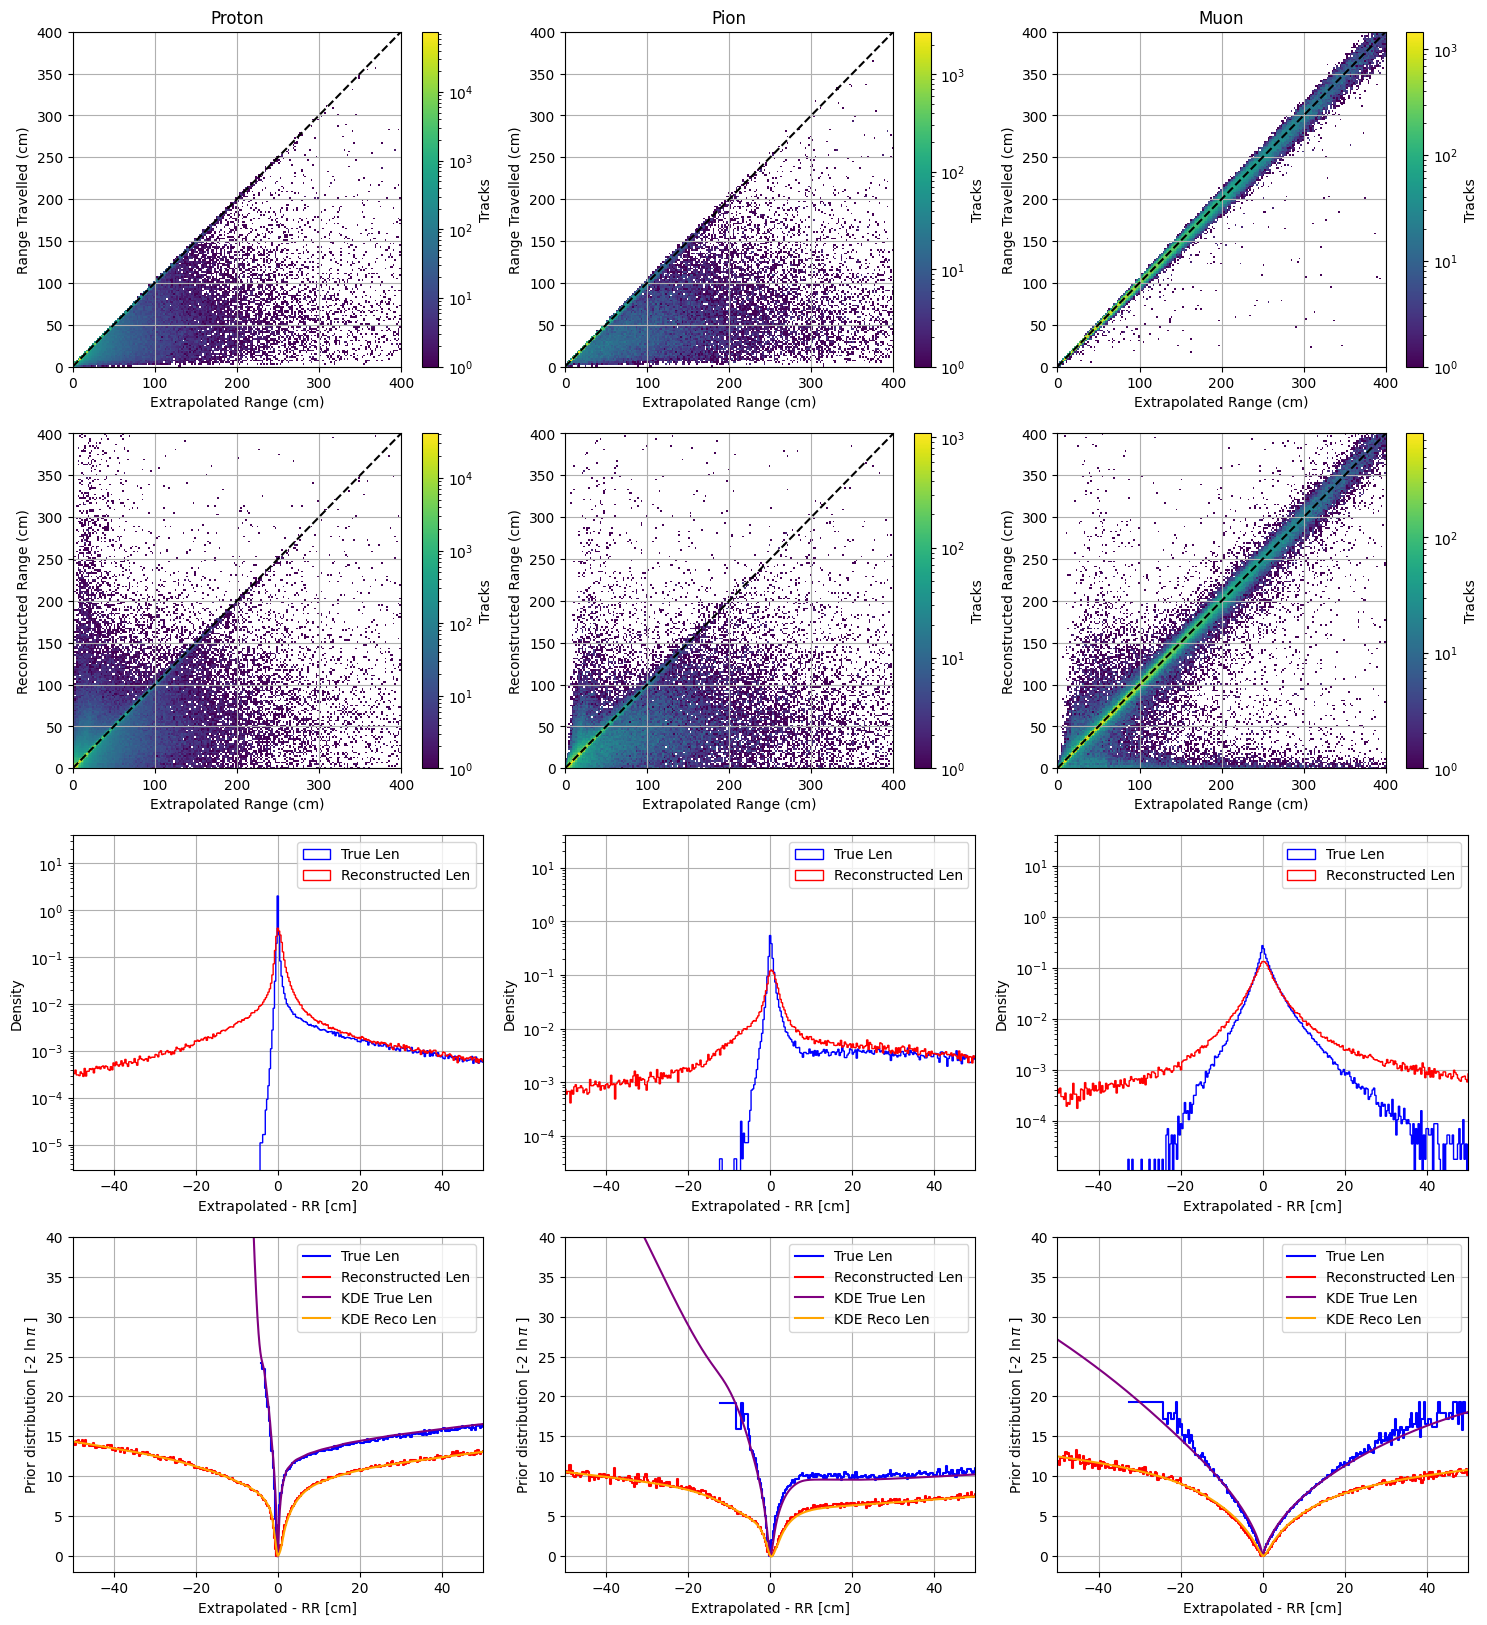

In [28]:
fig, ax = plt.subplots(4,3, figsize=(18, 20))
ax = ax.flatten()

rr_bins = np.linspace(0, 400, 201)   # 2 cm bins, same for x and y

def rr_hist2d(a, x, y, ylabel, title=None):
    h = a.hist2d(x, y, bins=[rr_bins, rr_bins], cmin=1 , norm=LogNorm())
    fig.colorbar(h[3], ax=a, label="Tracks")
    a.plot([0, rr_bins[-1]], [0, rr_bins[-1]], 'k--')
    a.set_xlabel("Extrapolated Range (cm)")
    a.set_ylabel(ylabel)
    if title:
        a.set_title(title)

# True length vs Extrapolated Range  #
rr_hist2d(ax[0], proton_vars[0], proton_vars[1], "Range Travelled (cm)", "Proton")
rr_hist2d(ax[1], pion_vars[0],   pion_vars[1],   "Range Travelled (cm)", "Pion")
rr_hist2d(ax[2], muon_vars[0],   muon_vars[1],   "Range Travelled (cm)", "Muon")

# Reconstructed length vs Extrapolated Range  #
rr_hist2d(ax[3], proton_vars[0], proton_vars[2], "Reconstructed Range (cm)")
rr_hist2d(ax[4], pion_vars[0],   pion_vars[2],   "Reconstructed Range (cm)")
rr_hist2d(ax[5], muon_vars[0],   muon_vars[2],   "Reconstructed Range (cm)")






# delta L given different RR definitions#
binning = np.linspace(-600, 1000, 5000)
proton_hist_truth = ax[6].hist(proton_vars[0] - proton_vars[1], histtype='step', bins = binning, label="True Len" ,color="blue", density=True)
proton_hist_reco = ax[6].hist(proton_vars[0] - proton_vars[2], histtype='step', bins = binning, label ="Reconstructed Len" ,color="red", density=True)
ax[6].set_xlabel(f"Extrapolated - RR [cm]")
ax[6].set_ylabel(f"Density")

pion_hist_truth = ax[7].hist(pion_vars[0] - pion_vars[1], histtype='step', bins =binning, label="True Len" ,color="blue", density=True)
pion_hist_reco = ax[7].hist(pion_vars[0] - pion_vars[2], histtype='step', bins = binning, label ="Reconstructed Len" ,color="red", density=True)
ax[7].set_xlabel(f"Extrapolated - RR [cm]")
ax[7].set_ylabel(f"Density")

muon_hist_truth = ax[8].hist(muon_vars[0] - muon_vars[1], histtype='step', bins = binning, label="True Len" ,color="blue", density=True)
muon_hist_reco = ax[8].hist(muon_vars[0] - muon_vars[2], histtype='step', bins = binning, label ="Reconstructed Len" ,color="red", density=True)
ax[8].set_xlabel(f"Extrapolated - RR [cm]")
ax[8].set_ylabel(f"Density")


# Delta L prior distributions#
proton_prior_truth = prior_from_hist(proton_hist_truth[0], proton_hist_truth[1])
proton_prior_reco = prior_from_hist(proton_hist_reco[0], proton_hist_reco[1])
ax[9].step(proton_prior_truth['centers'], proton_prior_truth["nlp"], color="blue", label="True Len" )
ax[9].step(proton_prior_reco['centers'], proton_prior_reco["nlp"], color="red", label ="Reconstructed Len" )
ax[9].set_xlabel(f"Extrapolated - RR [cm]")
ax[9].set_ylabel(f"Prior distribution [-2 $\ln \pi$ ]")


pion_prior_truth = prior_from_hist(pion_hist_truth[0], pion_hist_truth[1])
pion_prior_reco = prior_from_hist(pion_hist_reco[0], pion_hist_reco[1])
ax[10].step(pion_prior_truth['centers'], pion_prior_truth["nlp"], color="blue", label="True Len")
ax[10].step(pion_prior_reco['centers'], pion_prior_reco["nlp"], color="red", label ="Reconstructed Len" )
ax[10].set_xlabel(f"Extrapolated - RR [cm]")
ax[10].set_ylabel(f"Prior distribution [-2 $\ln \pi$ ]")



muon_prior_truth = prior_from_hist(muon_hist_truth[0], muon_hist_truth[1])
muon_prior_reco = prior_from_hist(muon_hist_reco[0], muon_hist_reco[1])
ax[11].step(muon_prior_truth['centers'], muon_prior_truth["nlp"], color="blue", label="True Len")
ax[11].step(muon_prior_reco['centers'], muon_prior_reco["nlp"], color="red", label ="Reconstructed Len" )
ax[11].set_xlabel(f"Extrapolated - RR [cm]")
ax[11].set_ylabel(f"Prior distribution [-2 $\ln \pi$ ]")



#Applying KDE to extrapolate smooth PDFs
kde_s = {"p": 1.0, "pi": 1.0, "mu": 0.1}     # asinh scale per hypothesis (cm)

# shared grid, uniform in asinh(x/0.1): ~0.001 cm steps at the peak, ~10 cm at 1000 cm; includes x = 0
x = np.union1d(0.1 * np.sinh(np.linspace(np.arcsinh(-600 / 0.1), np.arcsinh(1000 / 0.1), 2000)), [0.0])

proton_kde_truth = kde_prior(proton_vars[0] - proton_vars[1], s=kde_s["p"])(x)
proton_kde_reco  = kde_prior(proton_vars[0] - proton_vars[2], s=kde_s["p"])(x)
pion_kde_truth   = kde_prior(pion_vars[0] - pion_vars[1], s=kde_s["pi"])(x)
pion_kde_reco    = kde_prior(pion_vars[0] - pion_vars[2], s=kde_s["pi"])(x)
muon_kde_truth   = kde_prior(muon_vars[0] - muon_vars[1], s=kde_s["mu"])(x)
muon_kde_reco    = kde_prior(muon_vars[0] - muon_vars[2], s=kde_s["mu"])(x)

for a, yt, yr in zip(ax[9:12], (proton_kde_truth, pion_kde_truth, muon_kde_truth), (proton_kde_reco, pion_kde_reco, muon_kde_reco)):
    a.plot(x, yt, color="purple", label="KDE True Len")
    a.plot(x, yr, color="orange", label="KDE Reco Len")







for i in range(len(ax)):
    ax[i].grid()
    if i in (6, 7, 8):
        ax[i].set_yscale("log")
    if i >=6:
        ax[i].legend()
        # ax[i].set_yscale("log")
        ax[i].set_xlim(-50,50)
        ax[i].set_ylim(-2,40)

plt.show()

In [29]:
tables_dir = "/exp/sbnd/app/users/maxd/Analysis/LLPID_cafpyana/cafpyana/analysis_village/ll_pid/tables"

np.savez(f"{tables_dir}/dl_prior_kde_noCosmics_truthlen.npz", x=x, p=proton_kde_truth, pi=pion_kde_truth, mu=muon_kde_truth)
np.savez(f"{tables_dir}/dl_prior_kde_noCosmics_recolen.npz",  x=x, p=proton_kde_reco,  pi=pion_kde_reco,  mu=muon_kde_reco)


# 2. Reconstructed hit PDFs

The physically correct model for charged particle dE/dx comes from Vavilov theory, which has limits to Landau's distribution and Gaussian Distributions. When measuring these in SBND, we often find that due to these inelastic collisions, we find difficulty in reconstructing the true energy of the particle. This impacts the choice of PDF for energy deposited and evidently impacts the PID choice made at the end of reconstruction. We find because of these inelastic collisions and uncertainty in dE/dx modelling, the reconstructed PDFs do not match the analytic Vavilov/Landau PDFs perfectly. Below we will show how the reconstruction of the hit PDFs for true particles are reproduced for this analysis. 

We start by choosing a pure selection of stopping protons, pions, and muons, and evaluate the various Vavilov parameters which will be plotted as our reconstructed PDFs. The choice of stopping particles is essential for our residual range correction, because we wish to "penalize" stopping particles without residual range correction. When we construct the hit PDF for our non-residual range corrected ($\Delta_L=0$), we will include these populations of contained particles in order to gain a representative sample of particles available. Below we will show three separate distributions: 

1. Hit PDFs for stopping particles - used for rr-corrected likelihood, $\ell_{hyp}$

2. Hit PDFs for contained particles - used for uncorrected range likelihood, $\ell_{0, hyp}$

3. Analytic Vavilov/Landau PDF - used to motivate the variables

In [ ]:
file = "/pnfs/sbnd/scratch/users/maxd/cafpyana_out/dfs/2026_10_16_124625__100k_MC_trkhit_run1gen2/100k_MC_trkhit_run1gen2_0.df"
hit_plane=2
df_hit = pd.read_hdf(file, key=rf"/hit{hit_plane}_0") 

n = 2 #number of first and last hits to ignore per track. Oftentimes inefficiencies with choosing first and last hit in Pandora 
df_hit = df_hit[(df_hit.groupby(level=[0,1,2,3]).cumcount() >= n) & (df_hit.groupby(level=[0,1,2,3]).cumcount(ascending=False) >= n)]
# df_hit = df_hit[df_hit["dedx"] < 40]
# df_hit = df_hit[df_hit["pitch"] < 0.65]

df_evt = pd.read_hdf(file, key="/evt_0")

df_evt = df_evt[(df_evt["slc", "is_clear_cosmic"] == 0) & (df_evt["pfp", "trk", "truth", "p", "cont_tpc",] == 1)]

p_df = df_evt[df_evt["pfp", "trk", "truth", "p", "pdg"] == 2212]
mu_df = df_evt[np.abs(df_evt["pfp", "trk", "truth", "p", "pdg"]) == 13]
pi_df = df_evt[np.abs(df_evt["pfp", "trk", "truth", "p", "pdg"]) == 211]
print(f"Protons: {len(p_df)}, Muons: {len(mu_df)}, Pions: {len(pi_df)}")

# Stopped Proton: 
p_df = p_df[~p_df["pfp", "trk", "truth", "p", "end_process"].isin([7, 8, 9, 10])]
mu_df = mu_df[~mu_df["pfp", "trk", "truth", "p", "end_process"].isin([7, 8, 9, 10])]
pi_df = pi_df[~pi_df["pfp", "trk", "truth", "p", "end_process"].isin([7, 8, 9, 10])]
print(f"Protons: {len(p_df)}, Muons: {len(mu_df)}, Pions: {len(pi_df)}")

#Removes many double tracks, where two particles are 
def end_match_dist(df):
    xyz = lambda *p: np.stack([df[p + (a,)].to_numpy() for a in "xyz"], axis=1)
    rs, re = xyz("pfp", "trk", "start"), xyz("pfp", "trk", "end")
    ts, te = xyz("pfp", "trk", "truth", "p", "start"), xyz("pfp", "trk", "truth", "p", "end")
    d = lambda a, b: np.linalg.norm(a - b, axis=1)
    # worst endpoint mismatch, removing events where Pandora flipped the track direction
    return np.maximum(d(rs, ts), d(re, te))



max_end_dist = 10  # cm
is_nu = lambda df: df["pfp", "trk", "truth", "p", "interaction_id"] >= 0  #Not a cosmic originating proton
p_df = p_df[is_nu(p_df) & (end_match_dist(p_df) < max_end_dist)]
pi_df = pi_df[is_nu(pi_df) & (end_match_dist(pi_df) < max_end_dist)]
mu_df = mu_df[is_nu(mu_df) & (end_match_dist(mu_df) < max_end_dist)]

print(f"Protons: {len(p_df)}, Muons: {len(mu_df)}, Pions: {len(pi_df)}")



Protons: 352, Muons: 83, Pions: 34
Protons: 295, Muons: 83, Pions: 24
Protons: 211, Muons: 68, Pions: 15


In [115]:
p_mask = df_hit.index.droplevel(rf'rec.slc.reco.pfp.trk.calo.{hit_plane}.points..index').isin(p_df.index)
p_df_hit = df_hit[p_mask]
p_df_hit = multicol_merge(df_hit, p_df, left_index=True, right_index=True, how="inner")

pi_mask = df_hit.index.droplevel(rf'rec.slc.reco.pfp.trk.calo.{hit_plane}.points..index').isin(pi_df.index)
pi_df_hit = df_hit[pi_mask]
pi_df_hit = multicol_merge(df_hit, pi_df, left_index=True, right_index=True, how="inner")

mu_mask = df_hit.index.droplevel(rf'rec.slc.reco.pfp.trk.calo.{hit_plane}.points..index').isin(mu_df.index)
mu_df_hit = df_hit[mu_mask]
mu_df_hit = multicol_merge(df_hit, mu_df, left_index=True, right_index=True, how="inner")


In [116]:
def append_variables(particle='p', particle_df_hit=p_df_hit):

    KE = llpid._ke_from_rr(llpid._ke_table(particle), particle_df_hit["rr"].to_numpy())           # MeV
    xi, kappa, beta2, mpv = llpid._pdf_params(KE, llpid.MASS[particle], particle_df_hit["pitch"].to_numpy())
    lam = (particle_df_hit["dedx"].to_numpy() - mpv) / xi                                    # Landau variable

    particle_df_hit["lam"] = lam
    particle_df_hit["kappa"] = kappa
    particle_df_hit["beta2"] = beta2
    return particle_df_hit

p_df_hit = append_variables('p', p_df_hit)
pi_df_hit = append_variables('pi', pi_df_hit)
mu_df_hit = append_variables('mu', mu_df_hit)


### 1. Hit PDF for Stopped Particles

In [24]:
#############################################################################
#  Same chunked skim as section 1, but for hits.
#  Per file: track cuts -> drop first/last n hits -> (lam, kappa, beta2) per species,
#  float32 and no index, so all files fit in memory
#############################################################################
hit_plane = 0
n = 2                # number of first and last hits to ignore per track. Oftentimes inefficiencies with choosing first and last hit in Pandora
max_end_dist = 10    # cm
# cut values are in the directory name, so changing a cut starts a fresh skim instead of resuming an old one
in_glob  = "/pnfs/sbnd/scratch/users/maxd/cafpyana_out/dfs/2026_10_16_124625__100k_MC_trkhit_run1gen2/100k_MC_trkhit_run1gen2_*.df"
hit_skim_dir = f"/exp/sbnd/data/users/maxd/llpid_skims/hitpdf_plane{hit_plane}_n{n}_end{max_end_dist}_100k_MC_trkhit_run1gen2"
os.makedirs(hit_skim_dir, exist_ok=True)

SPECIES = {"p": 2212, "pi": 211, "mu": 13}

def file_num(f):
    return int(re.search(r"_(\d+)\.df$", f).group(1))

chunk_size = 100

# Removes many double tracks, where two particles are reconstructed as one
def end_match_dist(df):
    xyz = lambda *p: np.stack([df[p + (a,)].to_numpy() for a in "xyz"], axis=1)
    rs, re = xyz("pfp", "trk", "start"), xyz("pfp", "trk", "end")
    ts, te = xyz("pfp", "trk", "truth", "p", "start"), xyz("pfp", "trk", "truth", "p", "end")
    d = lambda a, b: np.linalg.norm(a - b, axis=1)
    # worst endpoint mismatch, removing events where Pandora flipped the track direction
    return np.maximum(d(rs, ts), d(re, te))

is_nu = lambda df: df["pfp", "trk", "truth", "p", "interaction_id"] >= 0

def append_variables(particle, particle_df_hit):
    KE = llpid._ke_from_rr(llpid._ke_table(particle), particle_df_hit["rr"].to_numpy())           # MeV
    xi, kappa, beta2, mpv = llpid._pdf_params(KE, llpid.MASS[particle], particle_df_hit["pitch"].to_numpy())
    lam = (particle_df_hit["dedx"].to_numpy() - mpv) / xi                                    # Landau variable

    particle_df_hit["lam"] = lam
    particle_df_hit["kappa"] = kappa
    particle_df_hit["beta2"] = beta2
    return particle_df_hit

def skim_hits(fname):
    """One file -> {species: DataFrame(lam, kappa, beta2)} after the section-2 track cuts."""
    out = {s: [] for s in SPECIES}
    for i in range(get_n_split(fname)):
        df_evt = pd.read_hdf(fname, key=f"evt_{i}")
        df_evt = df_evt[(df_evt["slc", "is_clear_cosmic"] == 0) & (df_evt["pfp", "trk", "truth", "p", "cont_tpc"] == 1)]
        df_evt = df_evt[~df_evt["pfp", "trk", "truth", "p", "end_process"].isin([7, 8, 9, 10])]   # stopping
        df_evt = df_evt[is_nu(df_evt) & (end_match_dist(df_evt) < max_end_dist)]
        pdg = np.abs(df_evt["pfp", "trk", "truth", "p", "pdg"])

        df_hit = pd.read_hdf(fname, key=f"hit{hit_plane}_{i}")[["dedx", "rr", "pitch"]]
        g = df_hit.groupby(level=[0, 1, 2, 3])
        df_hit = df_hit[(g.cumcount() >= n) & (g.cumcount(ascending=False) >= n)]
        trk = df_hit.index.droplevel(-1)

        for s, code in SPECIES.items():
            h = append_variables(s, df_hit[trk.isin(df_evt.index[pdg == code])].copy())
            out[s].append(h[["lam", "kappa", "beta2"]].astype("float32").reset_index(drop=True))
    return {s: pd.concat(v, ignore_index=True) for s, v in out.items()}

files = sorted(glob.glob(in_glob), key=file_num)
for ichunk in range(0, len(files), chunk_size):
    out_name = f"{hit_skim_dir}/chunk_{ichunk // chunk_size:03d}.h5"
    if os.path.exists(out_name):
        continue                                  # already done, resume
    parts = {s: [] for s in SPECIES}
    for f in files[ichunk:ichunk + chunk_size]:
        try:
            for s, h in skim_hits(f).items():
                parts[s].append(h)
        except Exception as e:
            print(f"  skipping {f}: {e}")
    with pd.HDFStore(out_name + ".tmp", mode="w") as store:
        for s in SPECIES:
            store.put(s, pd.concat(parts[s], ignore_index=True))
    os.replace(out_name + ".tmp", out_name)       # only a finished chunk gets the real name
    print(f"wrote {out_name}: " + ", ".join(f"{s} {sum(map(len, parts[s])):,}" for s in SPECIES))


wrote /exp/sbnd/data/users/maxd/llpid_skims/hitpdf_plane0_n2_end10_100k_MC_trkhit_run1gen2/chunk_000.h5: p 447,536, pi 78,056, mu 1,334,530
wrote /exp/sbnd/data/users/maxd/llpid_skims/hitpdf_plane0_n2_end10_100k_MC_trkhit_run1gen2/chunk_001.h5: p 434,073, pi 77,335, mu 1,284,789
wrote /exp/sbnd/data/users/maxd/llpid_skims/hitpdf_plane0_n2_end10_100k_MC_trkhit_run1gen2/chunk_002.h5: p 443,620, pi 75,674, mu 1,294,546
wrote /exp/sbnd/data/users/maxd/llpid_skims/hitpdf_plane0_n2_end10_100k_MC_trkhit_run1gen2/chunk_003.h5: p 440,911, pi 77,944, mu 1,325,238
wrote /exp/sbnd/data/users/maxd/llpid_skims/hitpdf_plane0_n2_end10_100k_MC_trkhit_run1gen2/chunk_004.h5: p 435,391, pi 74,420, mu 1,285,327
wrote /exp/sbnd/data/users/maxd/llpid_skims/hitpdf_plane0_n2_end10_100k_MC_trkhit_run1gen2/chunk_005.h5: p 441,841, pi 74,664, mu 1,292,975
wrote /exp/sbnd/data/users/maxd/llpid_skims/hitpdf_plane0_n2_end10_100k_MC_trkhit_run1gen2/chunk_006.h5: p 443,555, pi 75,568, mu 1,277,715
wrote /exp/sbnd/data

In [25]:
chunks = sorted(glob.glob(f"{hit_skim_dir}/chunk_*.h5"))
p_df_hit, pi_df_hit, mu_df_hit = (pd.concat([pd.read_hdf(f, key=s) for f in chunks], ignore_index=True) for s in ("p", "pi", "mu"))
print(f"Proton hits: {len(p_df_hit):,}, Pion hits: {len(pi_df_hit):,}, Muon hits: {len(mu_df_hit):,}")


Proton hits: 8,886,423, Pion hits: 1,536,633, Muon hits: 26,333,438


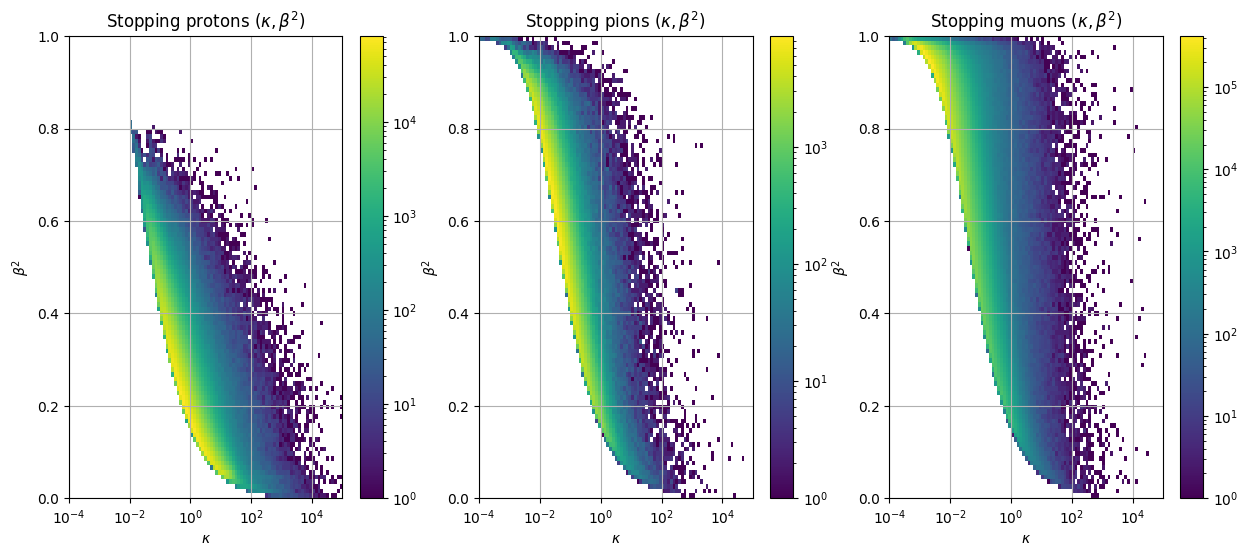

In [26]:
fig, ax = plt.subplots(1,3, figsize=(15, 6))
ax = ax.flatten()

*_, im0 = ax[0].hist2d(p_df_hit['kappa'], p_df_hit['beta2'], bins=(np.logspace(-4, 5, 100), np.linspace(0,1, 100)), norm=LogNorm())
ax[0].set_ylabel(r"$\beta^2$")
ax[0].set_xlabel(r"$\kappa$")
ax[0].set_xscale('log')
ax[0].set_title(r"Stopping protons ($\kappa, \beta^2$)")
ax[0].grid()
fig.colorbar(im0, ax=ax[0])

*_, im1 = ax[1].hist2d(pi_df_hit['kappa'], pi_df_hit['beta2'], bins=(np.logspace(-4, 5, 100), np.linspace(0,1, 100)), norm=LogNorm())
ax[1].set_ylabel(r"$\beta^2$")
ax[1].set_xlabel(r"$\kappa$")
ax[1].set_xscale('log')
ax[1].set_title(r"Stopping pions ($\kappa, \beta^2$)")
ax[1].grid()
fig.colorbar(im1, ax=ax[1])

*_, im2 = ax[2].hist2d(mu_df_hit['kappa'], mu_df_hit['beta2'], bins=(np.logspace(-4, 5, 100), np.linspace(0,1, 100)), norm=LogNorm())
ax[2].set_ylabel(r"$\beta^2$")
ax[2].set_xlabel(r"$\kappa$")
ax[2].set_xscale('log')
ax[2].set_title(r"Stopping muons ($\kappa, \beta^2$)")
ax[2].grid()
fig.colorbar(im2, ax=ax[2])

plt.show()

The spread in this plot is directly related to the pitch. The strong yellow band comes from normal pitches and the further from the main band requires larger and larger pitches. 

We choose to keep the high pitches since this is a true artifact of particles in our detector. This is one contribution to the shoulder on the landau parameter $\lambda$ seen below.



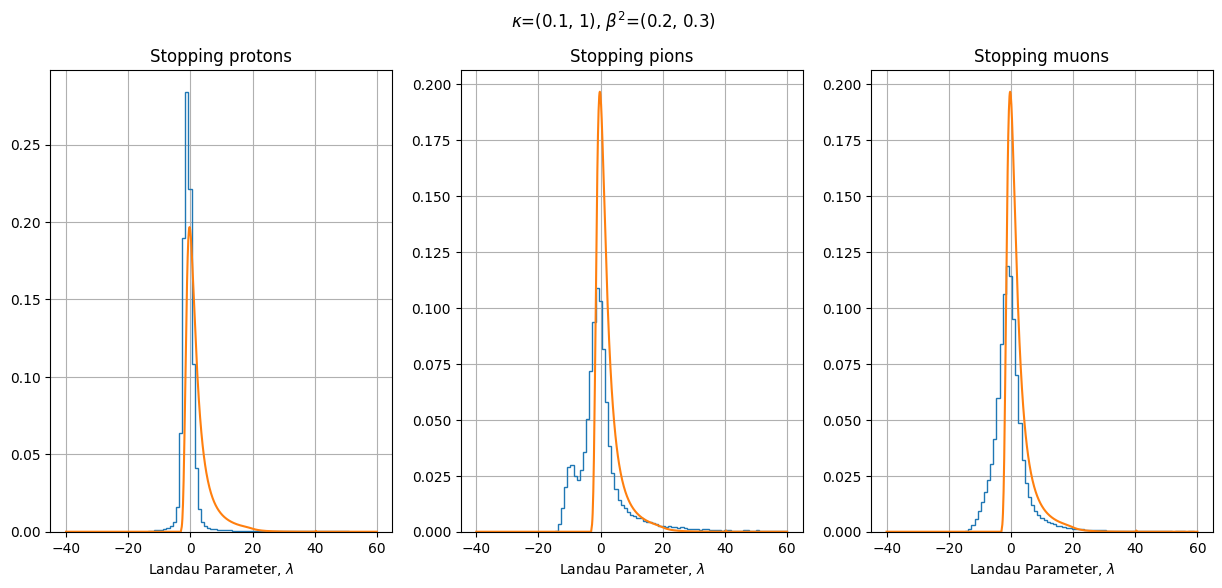

In [27]:
# Below demonstrates in a small band of Vavilov parameter space, how the MC compares with Vavilov expectations


# kappa=(0.01, 0.05)
# beta = (0.55,0.65)
# k, b = 0.025, 0.6
kappa=(0.1, 1)
beta = (0.2,0.3)
k, b = 0.05, 0.25

xfunc = np.linspace(-40,60, 1000)
f = np.array([ROOT.Math.vavilov_accurate_pdf(x, kappa=k, beta2= b) for x in xfunc])

p_df_hit_select =  p_df_hit[(p_df_hit["kappa"].between(kappa[0], kappa[1])) & (p_df_hit["beta2"].between(beta[0], beta[1]))]
pi_df_hit_select =  pi_df_hit[(pi_df_hit["kappa"].between(kappa[0], kappa[1])) & (pi_df_hit["beta2"].between(beta[0], beta[1]))]
mu_df_hit_select =  mu_df_hit[(mu_df_hit["kappa"].between(kappa[0], kappa[1])) & (mu_df_hit["beta2"].between(beta[0], beta[1]))]


fig, ax = plt.subplots(1,3, figsize=(15, 6))
ax = ax.flatten()

ax[0].hist(p_df_hit_select['lam'], bins=np.linspace(-40,60,100), histtype='step', density=True)
ax[0].plot(xfunc, f)
ax[0].grid()
ax[0].set_title(rf"Stopping protons")
ax[0].set_xlabel(r"Landau Parameter, $\lambda$")
# ax[0].vlines(-7, 0,0.2, color='black')

ax[1].hist(pi_df_hit_select['lam'], bins=np.linspace(-40,60,100), histtype='step', density=True)
ax[1].plot(xfunc, f)
ax[1].grid()
ax[1].set_title("Stopping pions")
ax[1].set_xlabel(r"Landau Parameter, $\lambda$")


ax[2].hist(mu_df_hit_select['lam'], bins=np.linspace(-40,60,100), histtype='step', density=True)
ax[2].plot(xfunc, f)
ax[2].grid()
ax[2].set_title("Stopping muons")
ax[2].set_xlabel(r"Landau Parameter, $\lambda$")

plt.suptitle(rf"$\kappa$={kappa}, $\beta^2$={beta}")
plt.show()

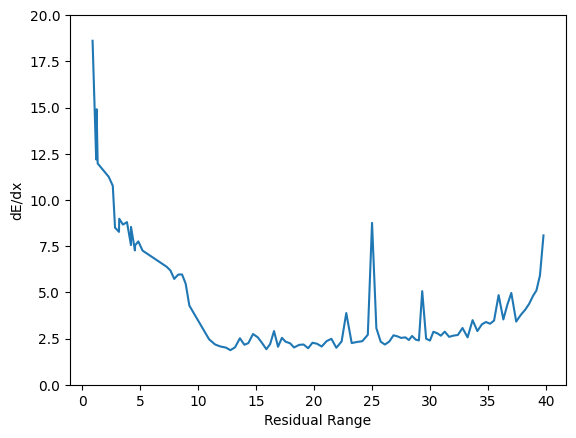

In [126]:
# Looking at weird tracks dE/dx vs rr, to see what is causing some anomalies in the landau parameter distributions

p_df_hit_fullodd = df_hit.sort_index().loc[(4, 7, 1, 0)] #Double track (Not found in proton sample anymore)

# p_df_hit_fullodd = p_df_hit.sort_index().loc[(4, 7, 1, 0)] #Double track (Removed from p_df_hit with endpoint cut)
# p_df_hit_fullodd = p_df_hit.sort_index().loc[(1,6,0,1	)] # Inelastic collision (Removed with truth end_process cut)
plt.plot(p_df_hit_fullodd["rr"], p_df_hit_fullodd['dedx'])
plt.ylabel("dE/dx")
plt.xlabel("Residual Range")
plt.ylim(0,20)
plt.show()

There are some of these unsightly abominations, where we have a proton and another particle combined into a single track. A cut we implement is a truth cut on the track start and end position are in agreement with the pfp truth per particle. This also removes many tracks that Pandora flips the track, which we will ignore in these PDFs, but will keep later in our PID since likelihood PID considers tracks being flipped. 

Below we construct the hit PDFs for each given particle species, which will be implemented into the hit likelihoods.  

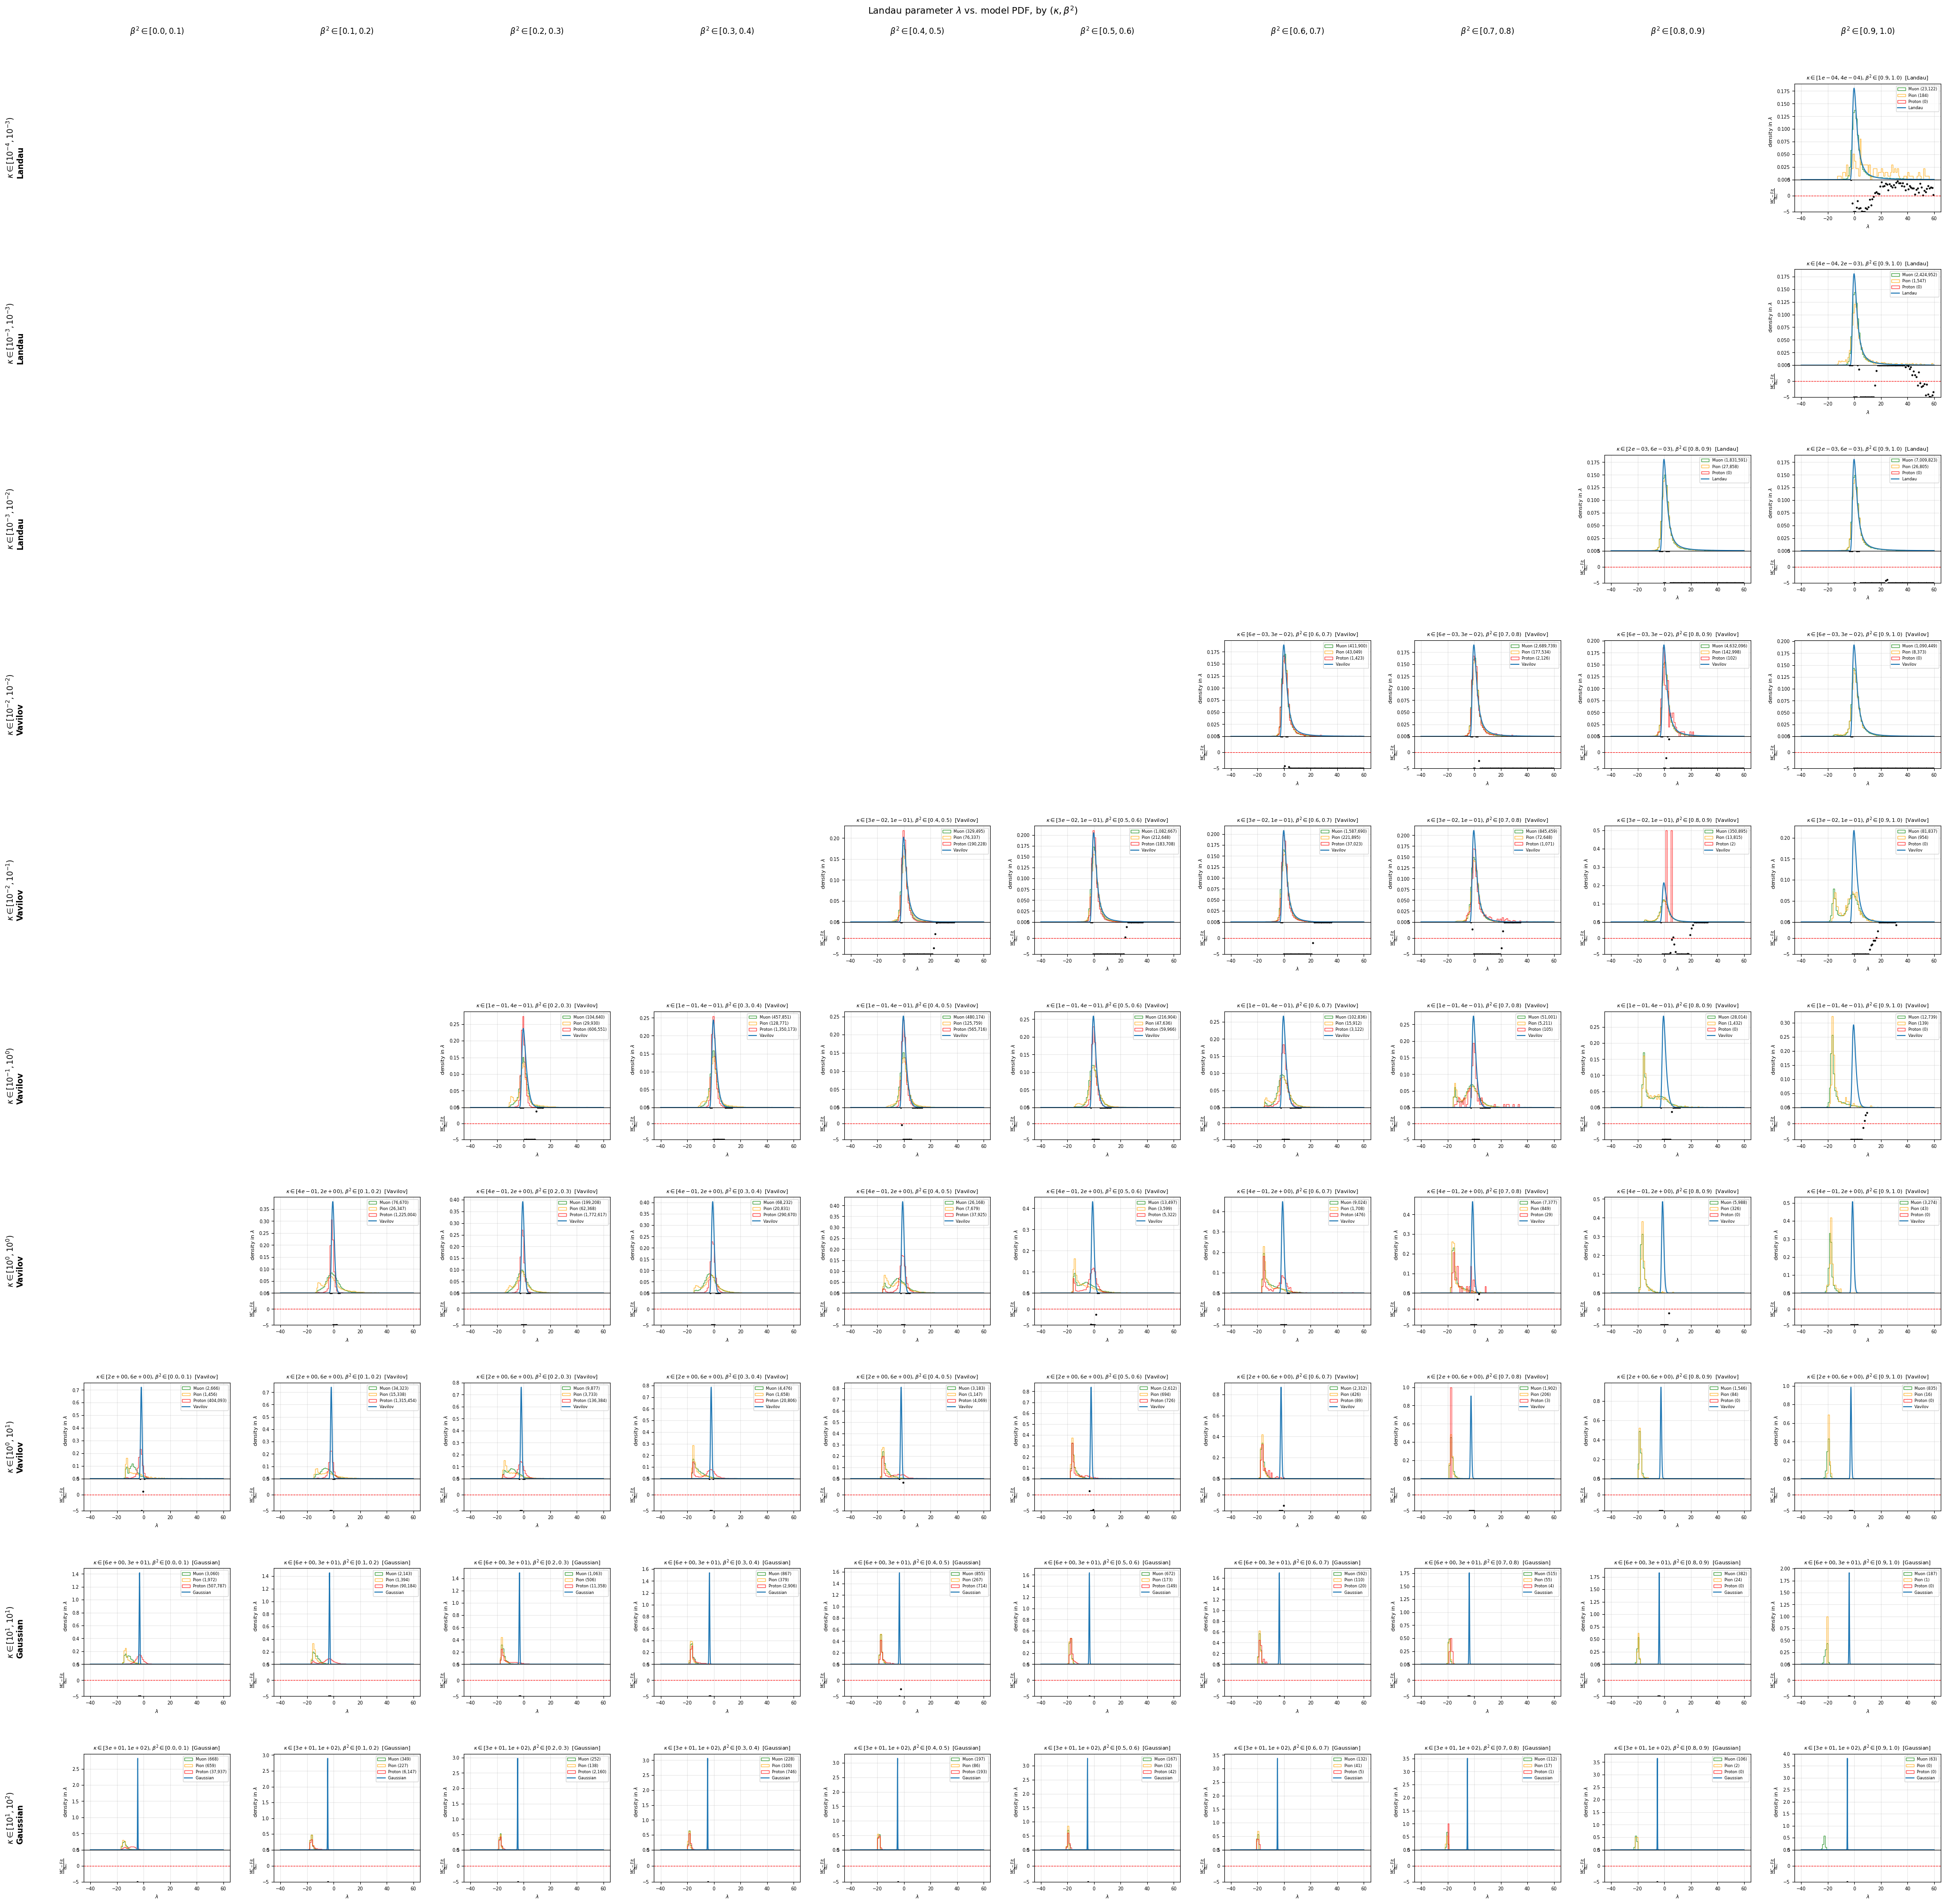

In [28]:
from scipy.stats import norm

samples = {"Proton": p_df_hit, "Pion": pi_df_hit, "Muon": mu_df_hit}
colors = {"Proton": "red", "Pion": "orange", "Muon": "green"}

kappa_edges = np.logspace(-4, 2, 11)          # rows: [1e-4, 1e-3) ... [10, 100)
beta_edges = np.linspace(0, 1, 11)           # columns: [0, 0.1) ... [0.9, 1)
lam_bins = np.linspace(-40, 60, 101)
bw = lam_bins[1] - lam_bins[0]
lam_c = 0.5 * (lam_bins[:-1] + lam_bins[1:])
x_fine = np.linspace(lam_bins[0], lam_bins[-1], 1000)
min_hits = 50

def regime(k):
    if k < 0.01:
        return "Landau"
    if k <= 10:
        return "Vavilov"
    return "Gaussian"

def model_pdf(x, k, b):
    r = regime(k)
    if r == "Landau":
        return np.array([ROOT.Math.landau_pdf(xi) for xi in x])
    if r == "Vavilov":
        return np.array([ROOT.Math.vavilov_accurate_pdf(xi, k, b) for xi in x])
    # large-κ limit of Vavilov: Gaussian with Vavilov's mean and variance in λ
    mean = np.euler_gamma - 1 - np.log(k) - b
    return norm.pdf(x, mean, np.sqrt((1 - b / 2) / k))

nrows, ncols = len(kappa_edges) - 1, len(beta_edges) - 1
fig = plt.figure(figsize=(4.2 * ncols, 4.2 * nrows))
outer = fig.add_gridspec(nrows, ncols, left=0.05, right=0.99, top=0.94, bottom=0.03, wspace=0.3, hspace=0.45)

for r, kappa in enumerate(zip(kappa_edges[:-1], kappa_edges[1:])):
    for c, beta in enumerate(zip(beta_edges[:-1], beta_edges[1:])):
        sels = {name: df.loc[df["kappa"].between(*kappa, inclusive="left") & df["beta2"].between(*beta, inclusive="left"), "lam"].to_numpy()
                for name, df in samples.items()}
        N = sum(len(v) for v in sels.values())
        if N < min_hits:
            continue

        k, b = np.sqrt(kappa[0] * kappa[1]), 0.5 * (beta[0] + beta[1])
        inner = outer[r, c].subgridspec(2, 1, height_ratios=[3, 1], hspace=0)
        ax = fig.add_subplot(inner[0])
        axp = fig.add_subplot(inner[1], sharex=ax)

        # species, stacked so the stack equals the total density
        names = list(sels)
        ax.hist([sels[n] for n in names], bins=lam_bins, stacked=False, histtype="step", alpha=0.7,
                # weights=[np.full(len(sels[n]), 1 / (N * bw)) for n in names],
                color=[colors[n] for n in names],
                label=[f"{n} ({len(sels[n]):,})" for n in names], density=True)

        # all hits as data points with Poisson errors
        counts, _ = np.histogram(np.concatenate(list(sels.values())), bins=lam_bins)
        dens, err = counts / (N * bw), np.sqrt(counts) / (N * bw)
        m = counts > 0
        # ax.errorbar(lam_c[m], dens[m], yerr=err[m], fmt="o", color="k", ms=2, elinewidth=0.8, label=f"Data ({N:,})")

        # model curve and pulls
        expected = N * bw * model_pdf(lam_c, k, b)
        use = expected > 1
        pull = (counts[use] - expected[use]) / np.sqrt(counts[use])
        chi2, ndf = np.sum(pull**2), use.sum()
        ax.plot(x_fine, model_pdf(x_fine, k, b), color="C0", lw=1.5, label=rf"{regime(k)} ")

        axp.plot(lam_c[use], np.clip(pull, -5, 5), "o", ms=2, color="k")
        axp.axhline(0, color="red", ls="--", lw=0.8)
        axp.set_ylim(-5, 5)

        ax.set_title(rf"$\kappa \in [{kappa[0]:.0e}, {kappa[1]:.0e})$, $\beta^2 \in [{beta[0]:.1f}, {beta[1]:.1f})$  [{regime(k)}]", fontsize=8)
        ax.set_ylabel(r"density in $\lambda$", fontsize=8)
        ax.tick_params(labelbottom=False, labelsize=7)
        ax.legend(fontsize=6, loc="upper right")
        ax.grid(alpha=0.3)
        axp.set_ylabel(r"$\frac{\text{MC} - \text{Fit}}{\sigma_{MC}} $", fontsize=8)
        axp.set_xlabel(r"$\lambda$", fontsize=8)
        axp.tick_params(labelsize=7)
        axp.grid(alpha=0.3)

# row and column labels, placed even where panels are missing
for r, kappa in enumerate(zip(kappa_edges[:-1], kappa_edges[1:])):
    bb = outer[r, 0].get_position(fig)
    k = np.sqrt(kappa[0] * kappa[1])
    fig.text(0.01, 0.5 * (bb.y0 + bb.y1),
             rf"$\kappa \in [10^{{{round(np.log10(kappa[0]))}}}, 10^{{{round(np.log10(kappa[1]))}}})$" + f"\n{regime(k)}",
             rotation=90, va="center", ha="left", fontsize=12, fontweight="bold")
for c, beta in enumerate(zip(beta_edges[:-1], beta_edges[1:])):
    bb = outer[0, c].get_position(fig)
    fig.text(0.5 * (bb.x0 + bb.x1), 0.965, rf"$\beta^2 \in [{beta[0]:.1f}, {beta[1]:.1f})$", ha="center", fontsize=12)

fig.suptitle(r"Landau parameter $\lambda$ vs. model PDF, by $(\kappa, \beta^2)$", fontsize=14)
plt.show()

In [29]:
#############################################################################
#  MC hit pdf table: pdf(lambda | kappa bin, beta2 bin) per plane and species.
#  A hit takes the pdf of the bin it falls in, no interpolation.
#############################################################################
from scipy import ndimage

tables_dir = "/exp/sbnd/app/users/maxd/Analysis/LLPID_cafpyana/cafpyana/analysis_village/ll_pid/tables"
planes   = [0,1,2]           # llpid needs every plane it is given; skim 0 and 1 the same way, then list them here
skim_dir = lambda pl: hit_skim_dir.replace(f"plane{hit_plane}", f"plane{pl}")
out_file = f"{tables_dir}/mc_pdf_binned_n{n}_end{max_end_dist}.npz"

lam_edges   = np.linspace(-40, 60, 201)                                                    # 0.5 wide
kap_edges   = np.r_[(np.arange(1, 10) * 10.0 ** np.arange(-4, 2)[:, None]).ravel(), 100.]  # 1e-4, 2e-4, ..., 0.6, 0.7, ..., 90, 100
beta2_edges = np.linspace(0, 1, 11)                                                        # 0.1 wide
edges = (lam_edges, kap_edges, beta2_edges)
dlam  = np.diff(lam_edges)[:, None, None]

min_cell = 400       # fewer hits than this in a (kappa, beta2) bin: borrow a shape
floor    = 1e-6      # keeps empty lambda bins from giving -2lnL = inf

def to_pdf(counts):
    nn = counts.sum(axis=0)
    with np.errstate(invalid="ignore", divide="ignore"):
        return counts / (nn * dlam), nn

out = {"lam_edges": lam_edges, "kap_edges": kap_edges, "beta2_edges": beta2_edges, "planes": np.array(planes)}
for pl in planes:
    counts = {s: np.zeros([len(e) - 1 for e in edges]) for s in SPECIES}
    for f in sorted(glob.glob(f"{skim_dir(pl)}/chunk_*.h5")):
        for s in SPECIES:
            d = pd.read_hdf(f, key=s)
            counts[s] += np.histogramdd(np.c_[d["lam"], d["kappa"], d["beta2"]], bins=edges)[0]
    counts["all"] = sum(counts.values())

    pdf_all, n_all = to_pdf(counts["all"])
    for s, c in counts.items():
        pdf, nn = to_pdf(c)
        pdf = np.where(nn >= min_cell, pdf, pdf_all)          # thin for this species: pooled species shape
        _, (ik, ib) = ndimage.distance_transform_edt((nn < min_cell) & (n_all < min_cell), return_indices=True)
        out[f"pdf_{pl}_{s}"] = np.maximum(pdf[:, ik, ib], floor)   # thin for all species: nearest filled bin
        out[f"n_{pl}_{s}"] = nn
        print(f"plane {pl} {s:>3}: {nn.sum():,.0f} hits, {(nn >= min_cell).sum()} of {nn.size} bins measured")

np.savez(out_file, **out)
print("wrote", out_file)


plane 0   p: 8,809,388 hits, 118 of 540 bins measured
plane 0  pi: 1,514,812 hits, 115 of 540 bins measured
plane 0  mu: 26,195,822 hits, 180 of 540 bins measured
plane 0 all: 36,520,022 hits, 219 of 540 bins measured
plane 1   p: 8,619,003 hits, 116 of 540 bins measured
plane 1  pi: 1,504,361 hits, 112 of 540 bins measured
plane 1  mu: 25,518,153 hits, 178 of 540 bins measured
plane 1 all: 35,641,517 hits, 217 of 540 bins measured
plane 2   p: 12,794,833 hits, 90 of 540 bins measured
plane 2  pi: 1,698,264 hits, 107 of 540 bins measured
plane 2  mu: 34,111,246 hits, 166 of 540 bins measured
plane 2 all: 48,604,343 hits, 199 of 540 bins measured
wrote /exp/sbnd/app/users/maxd/Analysis/LLPID_cafpyana/cafpyana/analysis_village/ll_pid/tables/mc_pdf_binned_n2_end10.npz


In [30]:
data = np.load("/exp/sbnd/app/users/maxd/Analysis/LLPID_cafpyana/cafpyana/analysis_village/ll_pid/tables/mc_pdf_binned_n2_end10.npz")
print(data.files)                 # names of the stored arrays

for name in data.files:
    print(name, data[name].shape, data[name].dtype)


['lam_edges', 'kap_edges', 'beta2_edges', 'planes', 'pdf_0_p', 'n_0_p', 'pdf_0_pi', 'n_0_pi', 'pdf_0_mu', 'n_0_mu', 'pdf_0_all', 'n_0_all', 'pdf_1_p', 'n_1_p', 'pdf_1_pi', 'n_1_pi', 'pdf_1_mu', 'n_1_mu', 'pdf_1_all', 'n_1_all', 'pdf_2_p', 'n_2_p', 'pdf_2_pi', 'n_2_pi', 'pdf_2_mu', 'n_2_mu', 'pdf_2_all', 'n_2_all']
lam_edges (201,) float64
kap_edges (55,) float64
beta2_edges (11,) float64
planes (3,) int64
pdf_0_p (200, 54, 10) float64
n_0_p (54, 10) float64
pdf_0_pi (200, 54, 10) float64
n_0_pi (54, 10) float64
pdf_0_mu (200, 54, 10) float64
n_0_mu (54, 10) float64
pdf_0_all (200, 54, 10) float64
n_0_all (54, 10) float64
pdf_1_p (200, 54, 10) float64
n_1_p (54, 10) float64
pdf_1_pi (200, 54, 10) float64
n_1_pi (54, 10) float64
pdf_1_mu (200, 54, 10) float64
n_1_mu (54, 10) float64
pdf_1_all (200, 54, 10) float64
n_1_all (54, 10) float64
pdf_2_p (200, 54, 10) float64
n_2_p (54, 10) float64
pdf_2_pi (200, 54, 10) float64
n_2_pi (54, 10) float64
pdf_2_mu (200, 54, 10) float64
n_2_mu (54, 

### 2. Hit PDF for all contained particles

We relax the stopped particle condition to allow for inelastic energy losses. This will be used for the bare likelihood as we want to account for these losses in the PDFs.

In [16]:
hit_plane = 2
n = 2                # number of first and last hits to ignore per track. Oftentimes inefficiencies with choosing first and last hit in Pandora
max_end_dist = 10    # cm
# cut values are in the directory name, so changing a cut starts a fresh skim instead of resuming an old one
in_glob  = "/pnfs/sbnd/scratch/users/maxd/cafpyana_out/dfs/2026_10_16_124625__100k_MC_trkhit_run1gen2/100k_MC_trkhit_run1gen2_*.df"
hit_skim_dir = f"/exp/sbnd/data/users/maxd/llpid_skims/hitpdf_nonstopped_plane{hit_plane}_n{n}_end{max_end_dist}_100k_MC_trkhit_run1gen2"
os.makedirs(hit_skim_dir, exist_ok=True)

SPECIES = {"p": 2212, "pi": 211, "mu": 13}

def file_num(f):
    return int(re.search(r"_(\d+)\.df$", f).group(1))

chunk_size = 100

# Removes many double tracks, where two particles are reconstructed as one
def end_match_dist(df):
    xyz = lambda *p: np.stack([df[p + (a,)].to_numpy() for a in "xyz"], axis=1)
    rs, re = xyz("pfp", "trk", "start"), xyz("pfp", "trk", "end")
    ts, te = xyz("pfp", "trk", "truth", "p", "start"), xyz("pfp", "trk", "truth", "p", "end")
    d = lambda a, b: np.linalg.norm(a - b, axis=1)
    # worst endpoint mismatch, removing events where Pandora flipped the track direction
    return np.maximum(d(rs, ts), d(re, te))

is_nu = lambda df: df["pfp", "trk", "truth", "p", "interaction_id"] >= 0

def append_variables(particle, particle_df_hit):
    KE = llpid._ke_from_rr(llpid._ke_table(particle), particle_df_hit["rr"].to_numpy())           # MeV
    xi, kappa, beta2, mpv = llpid._pdf_params(KE, llpid.MASS[particle], particle_df_hit["pitch"].to_numpy())
    lam = (particle_df_hit["dedx"].to_numpy() - mpv) / xi                                    # Landau variable

    particle_df_hit["lam"] = lam
    particle_df_hit["kappa"] = kappa
    particle_df_hit["beta2"] = beta2
    return particle_df_hit

def skim_hits(fname):
    """One file -> {species: DataFrame(lam, kappa, beta2)} after the section-2 track cuts."""
    out = {s: [] for s in SPECIES}
    for i in range(get_n_split(fname)):
        df_evt = pd.read_hdf(fname, key=f"evt_{i}")
        df_evt = df_evt[(df_evt["slc", "is_clear_cosmic"] == 0) & (df_evt["pfp", "trk", "truth", "p", "cont_tpc"] == 1)]
        # df_evt = df_evt[~df_evt["pfp", "trk", "truth", "p", "end_process"].isin([7, 8, 9, 10])]   # stopping
        df_evt = df_evt[is_nu(df_evt) & (end_match_dist(df_evt) < max_end_dist)]
        pdg = np.abs(df_evt["pfp", "trk", "truth", "p", "pdg"])

        df_hit = pd.read_hdf(fname, key=f"hit{hit_plane}_{i}")[["dedx", "rr", "pitch"]]
        g = df_hit.groupby(level=[0, 1, 2, 3])
        df_hit = df_hit[(g.cumcount() >= n) & (g.cumcount(ascending=False) >= n)]
        trk = df_hit.index.droplevel(-1)

        for s, code in SPECIES.items():
            h = append_variables(s, df_hit[trk.isin(df_evt.index[pdg == code])].copy())
            out[s].append(h[["lam", "kappa", "beta2"]].astype("float32").reset_index(drop=True))
    return {s: pd.concat(v, ignore_index=True) for s, v in out.items()}

files = sorted(glob.glob(in_glob), key=file_num)
for ichunk in range(0, len(files), chunk_size):
    out_name = f"{hit_skim_dir}/chunk_{ichunk // chunk_size:03d}.h5"
    if os.path.exists(out_name):
        continue                                  # already done, resume
    parts = {s: [] for s in SPECIES}
    for f in files[ichunk:ichunk + chunk_size]:
        try:
            for s, h in skim_hits(f).items():
                parts[s].append(h)
        except Exception as e:
            print(f"  skipping {f}: {e}")
    with pd.HDFStore(out_name + ".tmp", mode="w") as store:
        for s in SPECIES:
            store.put(s, pd.concat(parts[s], ignore_index=True))
    os.replace(out_name + ".tmp", out_name)       # only a finished chunk gets the real name
    print(f"wrote {out_name}: " + ", ".join(f"{s} {sum(map(len, parts[s])):,}" for s in SPECIES))


wrote /exp/sbnd/data/users/maxd/llpid_skims/hitpdf_nonstopped_plane2_n2_end10_100k_MC_trkhit_run1gen2/chunk_000.h5: p 882,015, pi 224,871, mu 1,762,513
wrote /exp/sbnd/data/users/maxd/llpid_skims/hitpdf_nonstopped_plane2_n2_end10_100k_MC_trkhit_run1gen2/chunk_001.h5: p 868,428, pi 218,608, mu 1,684,098
wrote /exp/sbnd/data/users/maxd/llpid_skims/hitpdf_nonstopped_plane2_n2_end10_100k_MC_trkhit_run1gen2/chunk_002.h5: p 867,799, pi 207,123, mu 1,707,749
wrote /exp/sbnd/data/users/maxd/llpid_skims/hitpdf_nonstopped_plane2_n2_end10_100k_MC_trkhit_run1gen2/chunk_003.h5: p 867,389, pi 219,512, mu 1,708,323
wrote /exp/sbnd/data/users/maxd/llpid_skims/hitpdf_nonstopped_plane2_n2_end10_100k_MC_trkhit_run1gen2/chunk_004.h5: p 854,487, pi 198,423, mu 1,669,526
wrote /exp/sbnd/data/users/maxd/llpid_skims/hitpdf_nonstopped_plane2_n2_end10_100k_MC_trkhit_run1gen2/chunk_005.h5: p 875,327, pi 209,303, mu 1,659,431
wrote /exp/sbnd/data/users/maxd/llpid_skims/hitpdf_nonstopped_plane2_n2_end10_100k_MC_tr

In [17]:
chunks = sorted(glob.glob(f"{hit_skim_dir}/chunk_*.h5"))
p_df_hit, pi_df_hit, mu_df_hit = (pd.concat([pd.read_hdf(f, key=s) for f in chunks], ignore_index=True) for s in ("p", "pi", "mu"))
print(f"Proton hits: {len(p_df_hit):,}, Pion hits: {len(pi_df_hit):,}, Muon hits: {len(mu_df_hit):,}")


Proton hits: 17,604,949, Pion hits: 4,269,233, Muon hits: 34,381,803


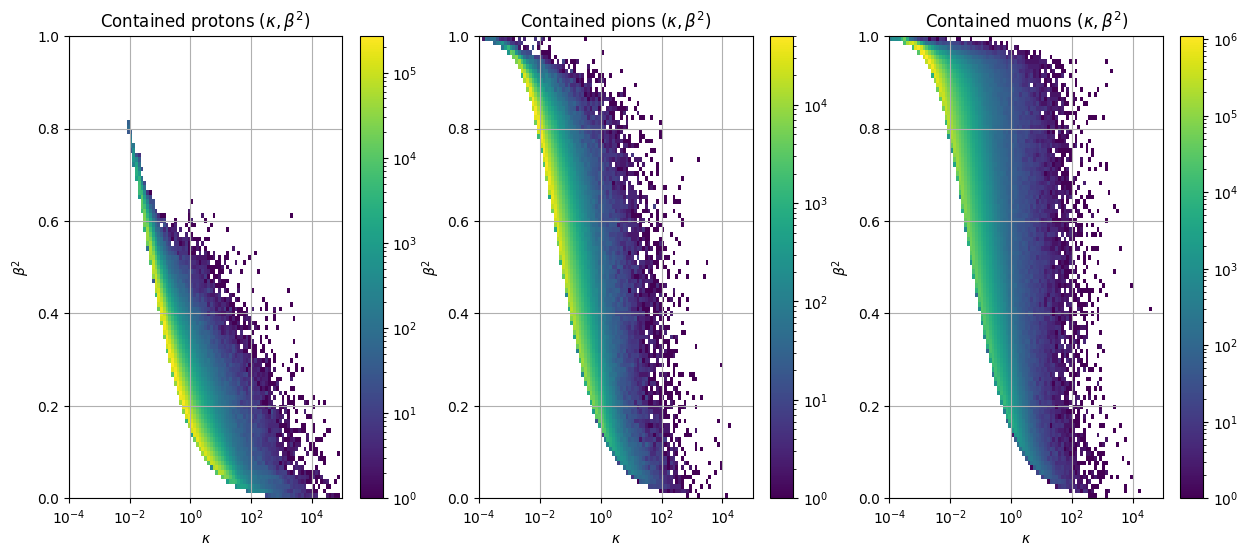

In [30]:
fig, ax = plt.subplots(1,3, figsize=(15, 6))
ax = ax.flatten()

*_, im0 = ax[0].hist2d(p_df_hit['kappa'], p_df_hit['beta2'], bins=(np.logspace(-4, 5, 100), np.linspace(0,1, 100)), norm=LogNorm())
ax[0].set_ylabel(r"$\beta^2$")
ax[0].set_xlabel(r"$\kappa$")
ax[0].set_xscale('log')
ax[0].set_title(r"Contained protons ($\kappa, \beta^2$)")
ax[0].grid()
fig.colorbar(im0, ax=ax[0])

*_, im1 = ax[1].hist2d(pi_df_hit['kappa'], pi_df_hit['beta2'], bins=(np.logspace(-4, 5, 100), np.linspace(0,1, 100)), norm=LogNorm())
ax[1].set_ylabel(r"$\beta^2$")
ax[1].set_xlabel(r"$\kappa$")
ax[1].set_xscale('log')
ax[1].set_title(r"Contained pions ($\kappa, \beta^2$)")
ax[1].grid()
fig.colorbar(im1, ax=ax[1])

*_, im2 = ax[2].hist2d(mu_df_hit['kappa'], mu_df_hit['beta2'], bins=(np.logspace(-4, 5, 100), np.linspace(0,1, 100)), norm=LogNorm())
ax[2].set_ylabel(r"$\beta^2$")
ax[2].set_xlabel(r"$\kappa$")
ax[2].set_xscale('log')
ax[2].set_title(r"Contained muons ($\kappa, \beta^2$)")
ax[2].grid()
fig.colorbar(im2, ax=ax[2])

plt.show()

The spread in this plot is directly related to the pitch. The strong yellow band comes from normal pitches and the further from the main band requires larger and larger pitches. 

We choose to keep the high pitches since this is a true artifact of particles in our detector. This is one contribution to the shoulder on the landau parameter $\lambda$ seen below.



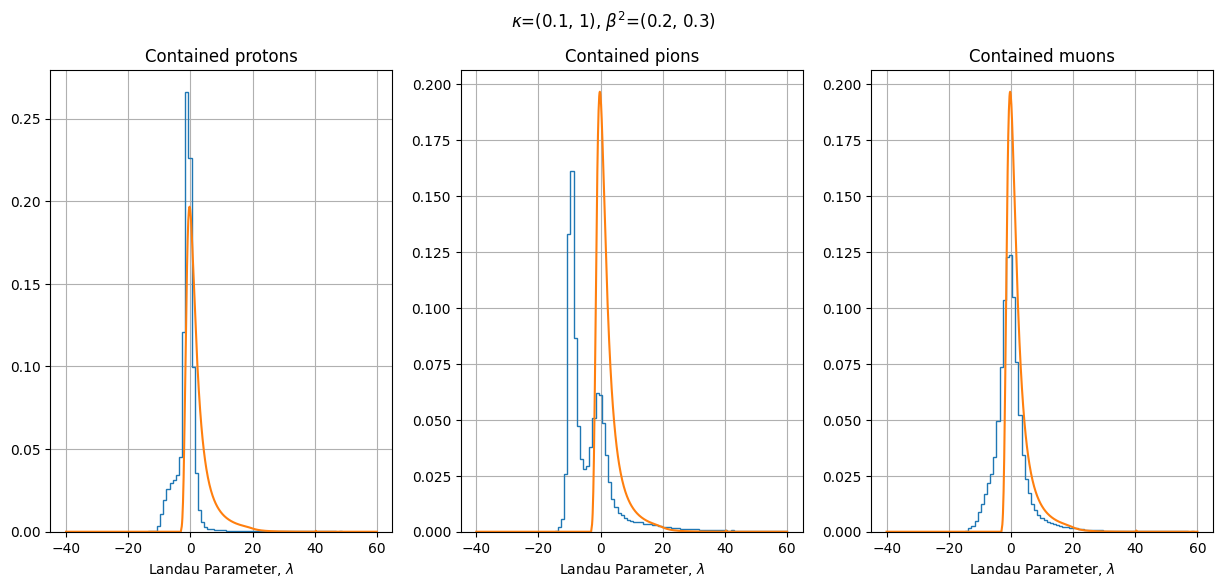

In [19]:
# Below demonstrates in a small band of Vavilov parameter space, how the MC compares with Vavilov expectations


# kappa=(0.01, 0.05)
# beta = (0.55,0.65)
# k, b = 0.025, 0.6
kappa=(0.1, 1)
beta = (0.2,0.3)
k, b = 0.05, 0.25

xfunc = np.linspace(-40,60, 1000)
f = np.array([ROOT.Math.vavilov_accurate_pdf(x, kappa=k, beta2= b) for x in xfunc])

p_df_hit_select =  p_df_hit[(p_df_hit["kappa"].between(kappa[0], kappa[1])) & (p_df_hit["beta2"].between(beta[0], beta[1]))]
pi_df_hit_select =  pi_df_hit[(pi_df_hit["kappa"].between(kappa[0], kappa[1])) & (pi_df_hit["beta2"].between(beta[0], beta[1]))]
mu_df_hit_select =  mu_df_hit[(mu_df_hit["kappa"].between(kappa[0], kappa[1])) & (mu_df_hit["beta2"].between(beta[0], beta[1]))]


fig, ax = plt.subplots(1,3, figsize=(15, 6))
ax = ax.flatten()

ax[0].hist(p_df_hit_select['lam'], bins=np.linspace(-40,60,100), histtype='step', density=True)
ax[0].plot(xfunc, f)
ax[0].grid()
ax[0].set_title(rf"Contained protons")
ax[0].set_xlabel(r"Landau Parameter, $\lambda$")
# ax[0].vlines(-7, 0,0.2, color='black')

ax[1].hist(pi_df_hit_select['lam'], bins=np.linspace(-40,60,100), histtype='step', density=True)
ax[1].plot(xfunc, f)
ax[1].grid()
ax[1].set_title("Contained pions")
ax[1].set_xlabel(r"Landau Parameter, $\lambda$")


ax[2].hist(mu_df_hit_select['lam'], bins=np.linspace(-40,60,100), histtype='step', density=True)
ax[2].plot(xfunc, f)
ax[2].grid()
ax[2].set_title("Contained muons")
ax[2].set_xlabel(r"Landau Parameter, $\lambda$")

plt.suptitle(rf"$\kappa$={kappa}, $\beta^2$={beta}")
plt.show()

Below we construct the hit PDFs for each given particle species, which will be implemented into the hit likelihoods.  

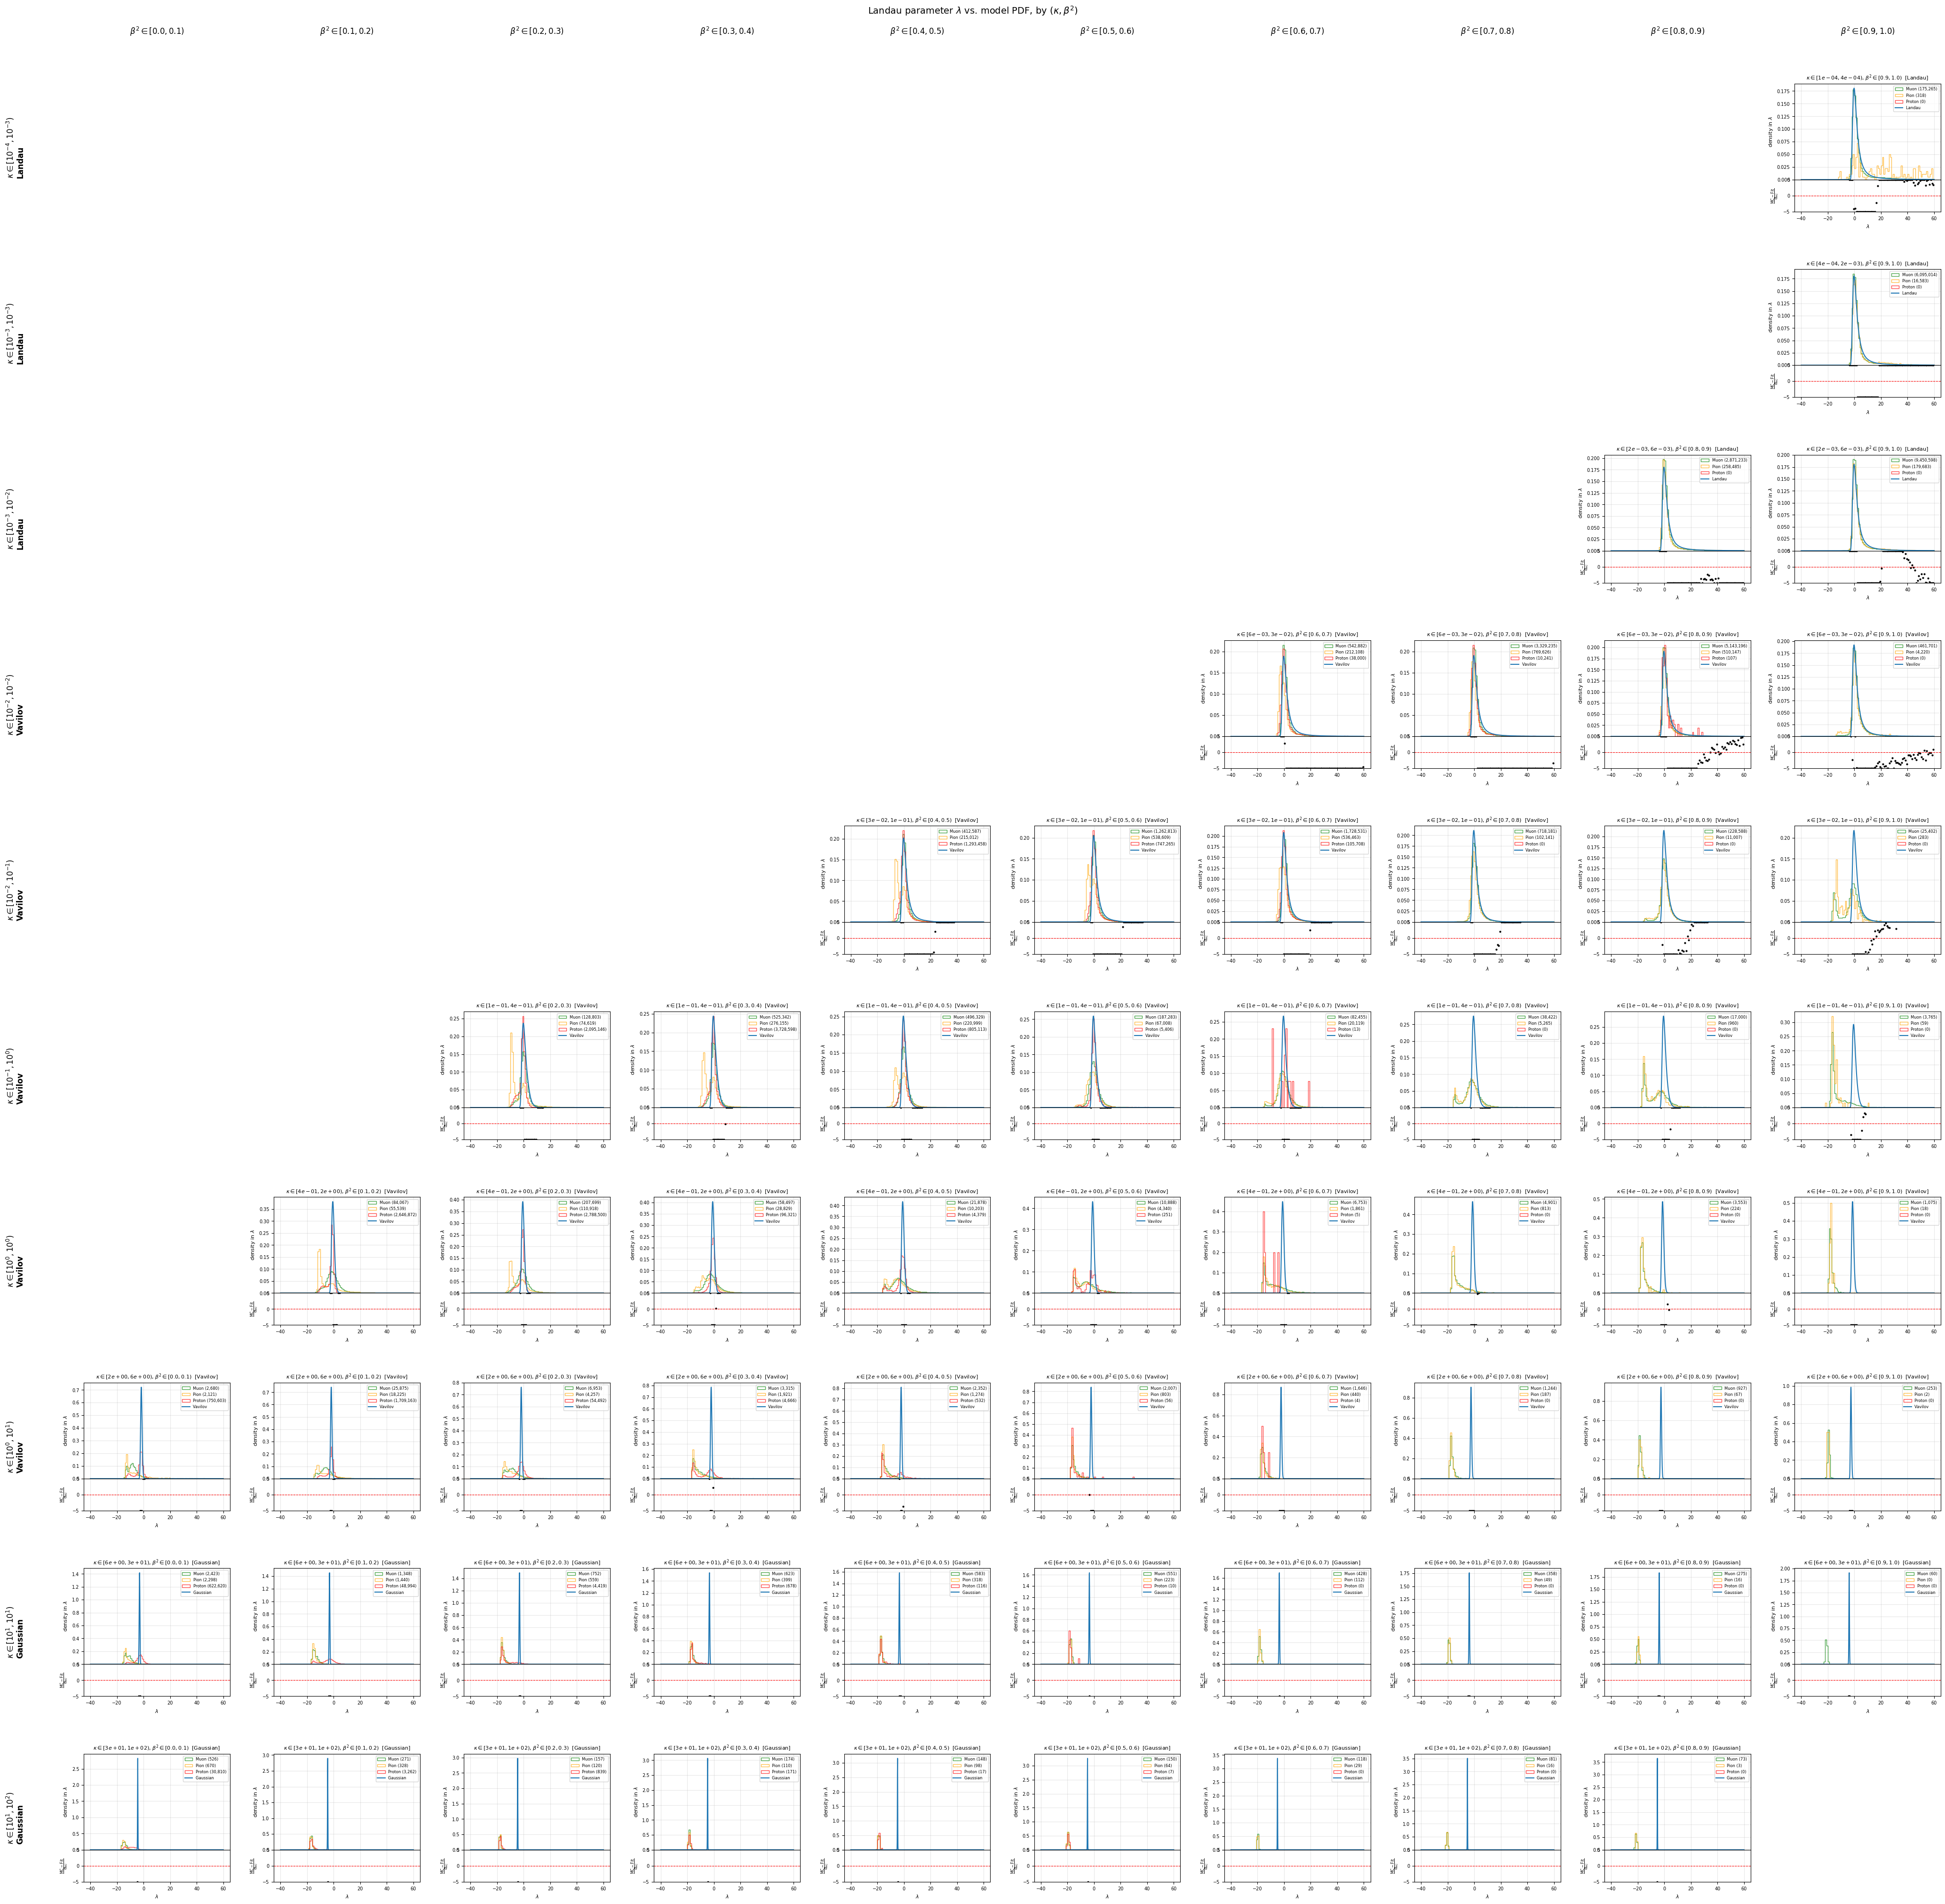

In [20]:
from scipy.stats import norm

samples = {"Proton": p_df_hit, "Pion": pi_df_hit, "Muon": mu_df_hit}
colors = {"Proton": "red", "Pion": "orange", "Muon": "green"}

kappa_edges = np.logspace(-4, 2, 11)          # rows: [1e-4, 1e-3) ... [10, 100)
beta_edges = np.linspace(0, 1, 11)           # columns: [0, 0.1) ... [0.9, 1)
lam_bins = np.linspace(-40, 60, 101)
bw = lam_bins[1] - lam_bins[0]
lam_c = 0.5 * (lam_bins[:-1] + lam_bins[1:])
x_fine = np.linspace(lam_bins[0], lam_bins[-1], 1000)
min_hits = 50

def regime(k):
    if k < 0.01:
        return "Landau"
    if k <= 10:
        return "Vavilov"
    return "Gaussian"

def model_pdf(x, k, b):
    r = regime(k)
    if r == "Landau":
        return np.array([ROOT.Math.landau_pdf(xi) for xi in x])
    if r == "Vavilov":
        return np.array([ROOT.Math.vavilov_accurate_pdf(xi, k, b) for xi in x])
    # large-κ limit of Vavilov: Gaussian with Vavilov's mean and variance in λ
    mean = np.euler_gamma - 1 - np.log(k) - b
    return norm.pdf(x, mean, np.sqrt((1 - b / 2) / k))

nrows, ncols = len(kappa_edges) - 1, len(beta_edges) - 1
fig = plt.figure(figsize=(4.2 * ncols, 4.2 * nrows))
outer = fig.add_gridspec(nrows, ncols, left=0.05, right=0.99, top=0.94, bottom=0.03, wspace=0.3, hspace=0.45)

for r, kappa in enumerate(zip(kappa_edges[:-1], kappa_edges[1:])):
    for c, beta in enumerate(zip(beta_edges[:-1], beta_edges[1:])):
        sels = {name: df.loc[df["kappa"].between(*kappa, inclusive="left") & df["beta2"].between(*beta, inclusive="left"), "lam"].to_numpy()
                for name, df in samples.items()}
        N = sum(len(v) for v in sels.values())
        if N < min_hits:
            continue

        k, b = np.sqrt(kappa[0] * kappa[1]), 0.5 * (beta[0] + beta[1])
        inner = outer[r, c].subgridspec(2, 1, height_ratios=[3, 1], hspace=0)
        ax = fig.add_subplot(inner[0])
        axp = fig.add_subplot(inner[1], sharex=ax)

        # species, stacked so the stack equals the total density
        names = list(sels)
        ax.hist([sels[n] for n in names], bins=lam_bins, stacked=False, histtype="step", alpha=0.7,
                # weights=[np.full(len(sels[n]), 1 / (N * bw)) for n in names],
                color=[colors[n] for n in names],
                label=[f"{n} ({len(sels[n]):,})" for n in names], density=True)

        # all hits as data points with Poisson errors
        counts, _ = np.histogram(np.concatenate(list(sels.values())), bins=lam_bins)
        dens, err = counts / (N * bw), np.sqrt(counts) / (N * bw)
        m = counts > 0
        # ax.errorbar(lam_c[m], dens[m], yerr=err[m], fmt="o", color="k", ms=2, elinewidth=0.8, label=f"Data ({N:,})")

        # model curve and pulls
        expected = N * bw * model_pdf(lam_c, k, b)
        use = expected > 1
        pull = (counts[use] - expected[use]) / np.sqrt(counts[use])
        chi2, ndf = np.sum(pull**2), use.sum()
        ax.plot(x_fine, model_pdf(x_fine, k, b), color="C0", lw=1.5, label=rf"{regime(k)} ")

        axp.plot(lam_c[use], np.clip(pull, -5, 5), "o", ms=2, color="k")
        axp.axhline(0, color="red", ls="--", lw=0.8)
        axp.set_ylim(-5, 5)

        ax.set_title(rf"$\kappa \in [{kappa[0]:.0e}, {kappa[1]:.0e})$, $\beta^2 \in [{beta[0]:.1f}, {beta[1]:.1f})$  [{regime(k)}]", fontsize=8)
        ax.set_ylabel(r"density in $\lambda$", fontsize=8)
        ax.tick_params(labelbottom=False, labelsize=7)
        ax.legend(fontsize=6, loc="upper right")
        ax.grid(alpha=0.3)
        axp.set_ylabel(r"$\frac{\text{MC} - \text{Fit}}{\sigma_{MC}} $", fontsize=8)
        axp.set_xlabel(r"$\lambda$", fontsize=8)
        axp.tick_params(labelsize=7)
        axp.grid(alpha=0.3)

# row and column labels, placed even where panels are missing
for r, kappa in enumerate(zip(kappa_edges[:-1], kappa_edges[1:])):
    bb = outer[r, 0].get_position(fig)
    k = np.sqrt(kappa[0] * kappa[1])
    fig.text(0.01, 0.5 * (bb.y0 + bb.y1),
             rf"$\kappa \in [10^{{{round(np.log10(kappa[0]))}}}, 10^{{{round(np.log10(kappa[1]))}}})$" + f"\n{regime(k)}",
             rotation=90, va="center", ha="left", fontsize=12, fontweight="bold")
for c, beta in enumerate(zip(beta_edges[:-1], beta_edges[1:])):
    bb = outer[0, c].get_position(fig)
    fig.text(0.5 * (bb.x0 + bb.x1), 0.965, rf"$\beta^2 \in [{beta[0]:.1f}, {beta[1]:.1f})$", ha="center", fontsize=12)

fig.suptitle(r"Landau parameter $\lambda$ vs. model PDF, by $(\kappa, \beta^2)$", fontsize=14)
plt.show()

In [21]:
#############################################################################
#  MC hit pdf table: pdf(lambda | kappa bin, beta2 bin) per plane and species.
#  A hit takes the pdf of the bin it falls in, no interpolation.
#############################################################################
from scipy import ndimage

tables_dir = "/exp/sbnd/app/users/maxd/Analysis/LLPID_cafpyana/cafpyana/analysis_village/ll_pid/tables"
planes   = [0,1,2]           # llpid needs every plane it is given; skim 0 and 1 the same way, then list them here
skim_dir = lambda pl: hit_skim_dir.replace(f"plane{hit_plane}", f"plane{pl}")
out_file = f"{tables_dir}/mc_bare_pdf_binned_n{n}_end{max_end_dist}.npz"

lam_edges   = np.linspace(-40, 60, 201)                                                    # 0.5 wide
kap_edges   = np.r_[(np.arange(1, 10) * 10.0 ** np.arange(-4, 2)[:, None]).ravel(), 100.]  # 1e-4, 2e-4, ..., 0.6, 0.7, ..., 90, 100
beta2_edges = np.linspace(0, 1, 11)                                                        # 0.1 wide
edges = (lam_edges, kap_edges, beta2_edges)
dlam  = np.diff(lam_edges)[:, None, None]

min_cell = 400       # fewer hits than this in a (kappa, beta2) bin: borrow a shape
floor    = 1e-6      # keeps empty lambda bins from giving -2lnL = inf

def to_pdf(counts):
    nn = counts.sum(axis=0)
    with np.errstate(invalid="ignore", divide="ignore"):
        return counts / (nn * dlam), nn

out = {"lam_edges": lam_edges, "kap_edges": kap_edges, "beta2_edges": beta2_edges, "planes": np.array(planes)}
for pl in planes:
    counts = {s: np.zeros([len(e) - 1 for e in edges]) for s in SPECIES}
    for f in sorted(glob.glob(f"{skim_dir(pl)}/chunk_*.h5")):
        for s in SPECIES:
            d = pd.read_hdf(f, key=s)
            counts[s] += np.histogramdd(np.c_[d["lam"], d["kappa"], d["beta2"]], bins=edges)[0]
    counts["all"] = sum(counts.values())

    pdf_all, n_all = to_pdf(counts["all"])
    for s, c in counts.items():
        pdf, nn = to_pdf(c)
        pdf = np.where(nn >= min_cell, pdf, pdf_all)          # thin for this species: pooled species shape
        _, (ik, ib) = ndimage.distance_transform_edt((nn < min_cell) & (n_all < min_cell), return_indices=True)
        out[f"pdf_{pl}_{s}"] = np.maximum(pdf[:, ik, ib], floor)   # thin for all species: nearest filled bin
        out[f"n_{pl}_{s}"] = nn
        print(f"plane {pl} {s:>3}: {nn.sum():,.0f} hits, {(nn >= min_cell).sum()} of {nn.size} bins measured")

np.savez(out_file, **out)
print("wrote", out_file)


plane 0   p: 11,566,050 hits, 126 of 540 bins measured
plane 0  pi: 3,169,115 hits, 128 of 540 bins measured
plane 0  mu: 26,195,822 hits, 180 of 540 bins measured
plane 0 all: 40,930,987 hits, 223 of 540 bins measured
plane 1   p: 11,328,022 hits, 122 of 540 bins measured
plane 1  pi: 3,119,579 hits, 129 of 540 bins measured
plane 1  mu: 25,518,153 hits, 178 of 540 bins measured
plane 1 all: 39,965,754 hits, 222 of 540 bins measured
plane 2   p: 17,477,360 hits, 92 of 540 bins measured
plane 2  pi: 4,210,922 hits, 117 of 540 bins measured
plane 2  mu: 34,111,246 hits, 166 of 540 bins measured
plane 2 all: 55,799,528 hits, 201 of 540 bins measured
wrote /exp/sbnd/app/users/maxd/Analysis/LLPID_cafpyana/cafpyana/analysis_village/ll_pid/tables/mc_bare_pdf_binned_n2_end10.npz


In [22]:
data = np.load("/exp/sbnd/app/users/maxd/Analysis/LLPID_cafpyana/cafpyana/analysis_village/ll_pid/tables/mc_bare_pdf_binned_n2_end10.npz")
print(data.files)                 # names of the stored arrays

for name in data.files:
    print(name, data[name].shape, data[name].dtype)


['lam_edges', 'kap_edges', 'beta2_edges', 'planes', 'pdf_0_p', 'n_0_p', 'pdf_0_pi', 'n_0_pi', 'pdf_0_mu', 'n_0_mu', 'pdf_0_all', 'n_0_all', 'pdf_1_p', 'n_1_p', 'pdf_1_pi', 'n_1_pi', 'pdf_1_mu', 'n_1_mu', 'pdf_1_all', 'n_1_all', 'pdf_2_p', 'n_2_p', 'pdf_2_pi', 'n_2_pi', 'pdf_2_mu', 'n_2_mu', 'pdf_2_all', 'n_2_all']
lam_edges (201,) float64
kap_edges (55,) float64
beta2_edges (11,) float64
planes (3,) int64
pdf_0_p (200, 54, 10) float64
n_0_p (54, 10) float64
pdf_0_pi (200, 54, 10) float64
n_0_pi (54, 10) float64
pdf_0_mu (200, 54, 10) float64
n_0_mu (54, 10) float64
pdf_0_all (200, 54, 10) float64
n_0_all (54, 10) float64
pdf_1_p (200, 54, 10) float64
n_1_p (54, 10) float64
pdf_1_pi (200, 54, 10) float64
n_1_pi (54, 10) float64
pdf_1_mu (200, 54, 10) float64
n_1_mu (54, 10) float64
pdf_1_all (200, 54, 10) float64
n_1_all (54, 10) float64
pdf_2_p (200, 54, 10) float64
n_2_p (54, 10) float64
pdf_2_pi (200, 54, 10) float64
n_2_pi (54, 10) float64
pdf_2_mu (200, 54, 10) float64
n_2_mu (54, 